In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
# plt.rcdefaults() 
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from generic_plotting_functions import *

import pandas as pd
import os
import numpy as np

from load_modisco import *
import json

In [2]:
nc14_model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

def get_pattern_matrices(out_folder, TFMODISCO_WINDOW, num_flanking_bases=1):
    h5_file = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"
    pattern_cwms, pattern_pwms = get_pattern_info(h5_file, num_flanking_bases=num_flanking_bases)
    return pattern_cwms, pattern_pwms
    
nc14_pattern_cwms, nc14_pattern_ppms = get_pattern_matrices(nc14_model_dir + '/ism_report_1_cutoff/', TFMODISCO_WINDOW=600, num_flanking_bases=4)

In [3]:
def compute_ic(cwm):
    # Normalize columns to probabilities
    probs = cwm / np.sum(cwm, axis=0, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        ic = 2 + np.nansum(probs * np.log2(probs), axis=0)
    return np.sum(ic)  # or np.mean(ic) for mean per position

def plot_weights(array, ax, title=None):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_ylim(0,2)

    ax.set_ylabel('Bits')
    ax.set_xlabel('Motif Position')
    
    if title:
        ax.set_title(title)
    # plt.show()

def compute_per_position_ic(ppm, background, pseudocount):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    alphabet_len = len(background)
    ic = ((np.log((ppm+pseudocount)/(1 + pseudocount*alphabet_len))/np.log(2))
          *ppm - (np.log(background)*background/np.log(2))[None,:])
    return np.sum(ic,axis=1)

def make_logo(ppm):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    background = np.array([0.29, 0.21, 0.21, 0.29])
    ic = compute_per_position_ic(ppm, background, 0.001)
    return ppm*ic[:, None]

def trim_cwm_indices(cwm, trim_threshold=0.3, flanking_bases=1):
    score = np.sum(np.abs(cwm), axis=1) 
    # cut off anything less than 30% of max score
    trim_thresh = np.max(score) * trim_threshold 
    pass_inds = np.where(score >= trim_thresh)[0]
    # include flanking 4 bases left and right
    start, end = max(np.min(pass_inds) - flanking_bases, 0), min(np.max(pass_inds) + flanking_bases + 1, len(score) + 1)
    # trimmed_cwm = cwm[start:end]
    return start, end

def reverse_complement_pwm(pwm):
    pwm_rc = pwm[::-1, :]
    pwm_rc = pwm_rc[:, [3, 2, 1, 0]]
    return pwm_rc

In [4]:
# trim the final Motif-8 PPM with some flanking bp
Motif_8_CWM = nc14_pattern_cwms['neg_patterns.pattern_6']['rev']
Motif_8_PPM = nc14_pattern_ppms['neg_patterns.pattern_6']['rev']
start, end = trim_cwm_indices(Motif_8_CWM)
final_Motif_8_PPM = Motif_8_PPM[start:end]

def final_logo_plot(ppm, ax, title):
    logo = make_logo(ppm)
    plot_weights(logo, ax, title)


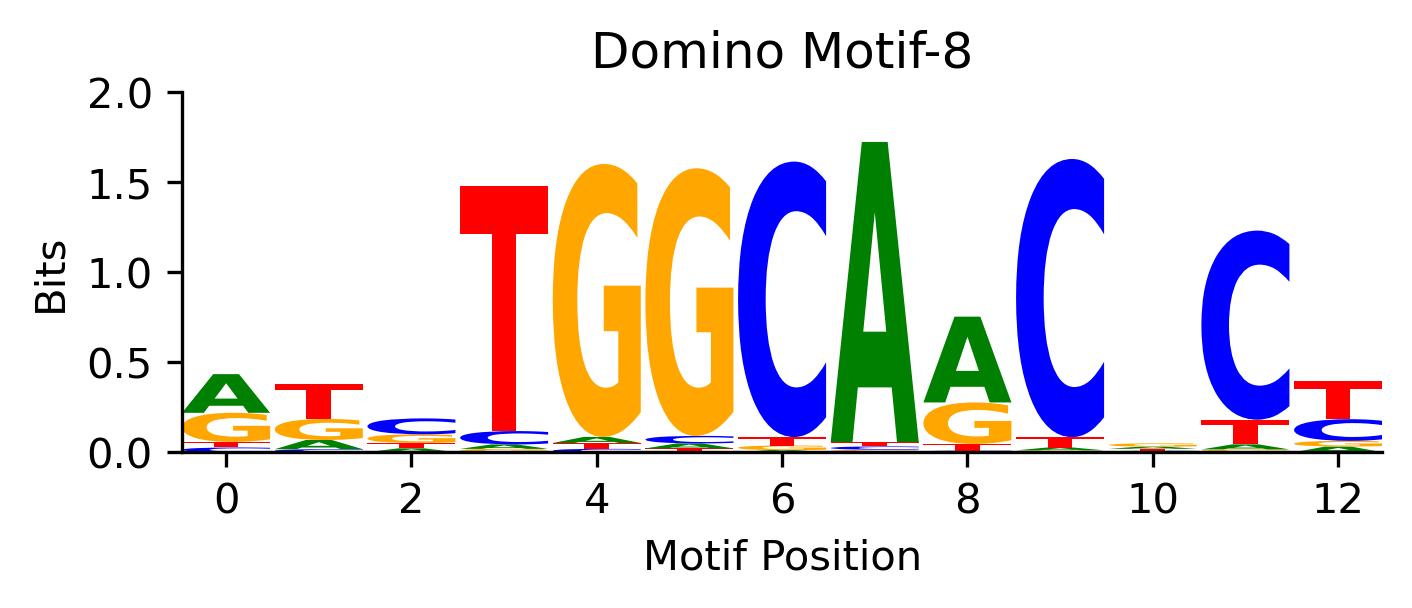

In [5]:
import logomaker
fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.3])
final_logo_plot(final_Motif_8_PPM, ax, 'Domino Motif-8')
# fig.savefig("plots/domino_motif_8.pdf", format="pdf", dpi=300, bbox_inches='tight')

### Read in MEME-ChIP motifs

In [6]:
import re

def get_evalues(meme_file):
    evalues = {}
    with open(meme_file) as f:
        motif = None
        for line in f:
            if line.startswith("MOTIF"):
                motif = line.split()[1]
            m = re.search(r"E\s*=\s*([0-9.eE+-]+)", line)
            if m and motif:
                evalues[motif] = float(m.group(1))
    
    return evalues

In [7]:
from memelite import tomtom
from memelite.io import read_meme

CG4854_meme_file = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/chip/0_CHIP_motif_8_candidates/meme_chip/CG4854_top_1000_output.ccut=200/combined.meme'
CG4854_peak_motifs = read_meme(CG4854_meme_file)
CG4854_Motif_8_PPM = reverse_complement_pwm(CG4854_peak_motifs['1 '].T)
CG4854_evalue = get_evalues(CG4854_meme_file)['1']


Trem_meme_file = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/chip/0_CHIP_motif_8_candidates/meme_chip/Trem_top_1000_output.ccut=200/combined.meme'
Trem_peak_motifs = read_meme(Trem_meme_file)
Trem_Motif_8_PPM = Trem_peak_motifs['0 '].T
Trem_evalue = get_evalues(Trem_meme_file)['0']



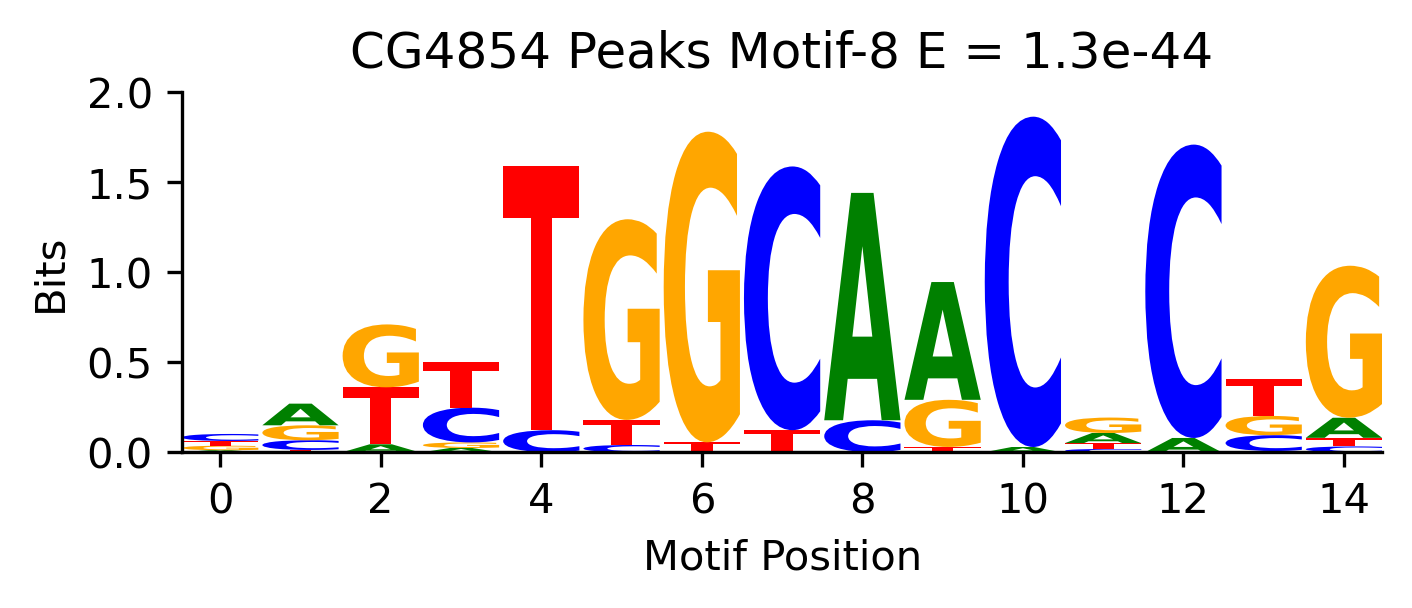

In [8]:
fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.3])
final_logo_plot(CG4854_Motif_8_PPM, ax, f'CG4854 Peaks Motif-8 E = {CG4854_evalue}')

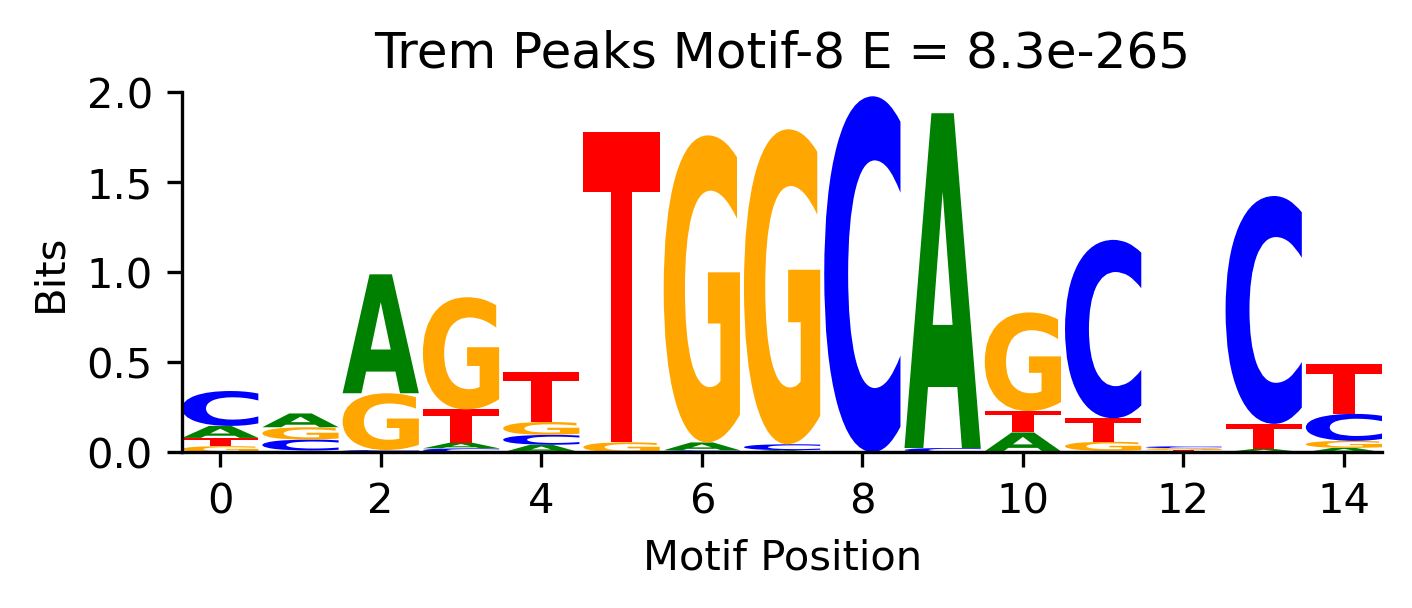

In [9]:
# had to fetch p-value from MEME file
fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.3])
final_logo_plot(Trem_Motif_8_PPM, ax, f'Trem Peaks Motif-8 E = {Trem_evalue}')

## Generate top motif matches

In [10]:
from memelite import tomtom
from memelite.io import read_meme

CG4854_meme_file = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/chip/0_CHIP_motif_8_candidates/meme_chip/CG4854_top_1000_output.ccut=200/combined.meme'
CG4854_peak_motifs = read_meme(CG4854_meme_file)
CG4854_evalues = get_evalues(CG4854_meme_file)

Trem_meme_file = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/chip/0_CHIP_motif_8_candidates/meme_chip/Trem_top_1000_output.ccut=200/combined.meme'
Trem_peak_motifs = read_meme(Trem_meme_file)
Trem_evalues = get_evalues(Trem_meme_file)


In [11]:
def plot_matches(meme_file, rc=False):
    peak_motifs = read_meme(meme_file)
    evalues = get_evalues(meme_file)
    num_motifs = len(evalues)
    fig, axs = init_subplots_exact(num_motifs, num_motifs, dpi=300, y_ratios=[0.3]*num_motifs, yspace=1.4)
    
    for i, (k, ppm) in enumerate(peak_motifs.items()):
        plot_ppm = ppm.T
        if rc:
            plot_ppm = reverse_complement_pwm(ppm.T)
        final_logo_plot(plot_ppm, axs[i], f'Motif Match #{i+1} | E-value = {evalues[k.strip()]}')



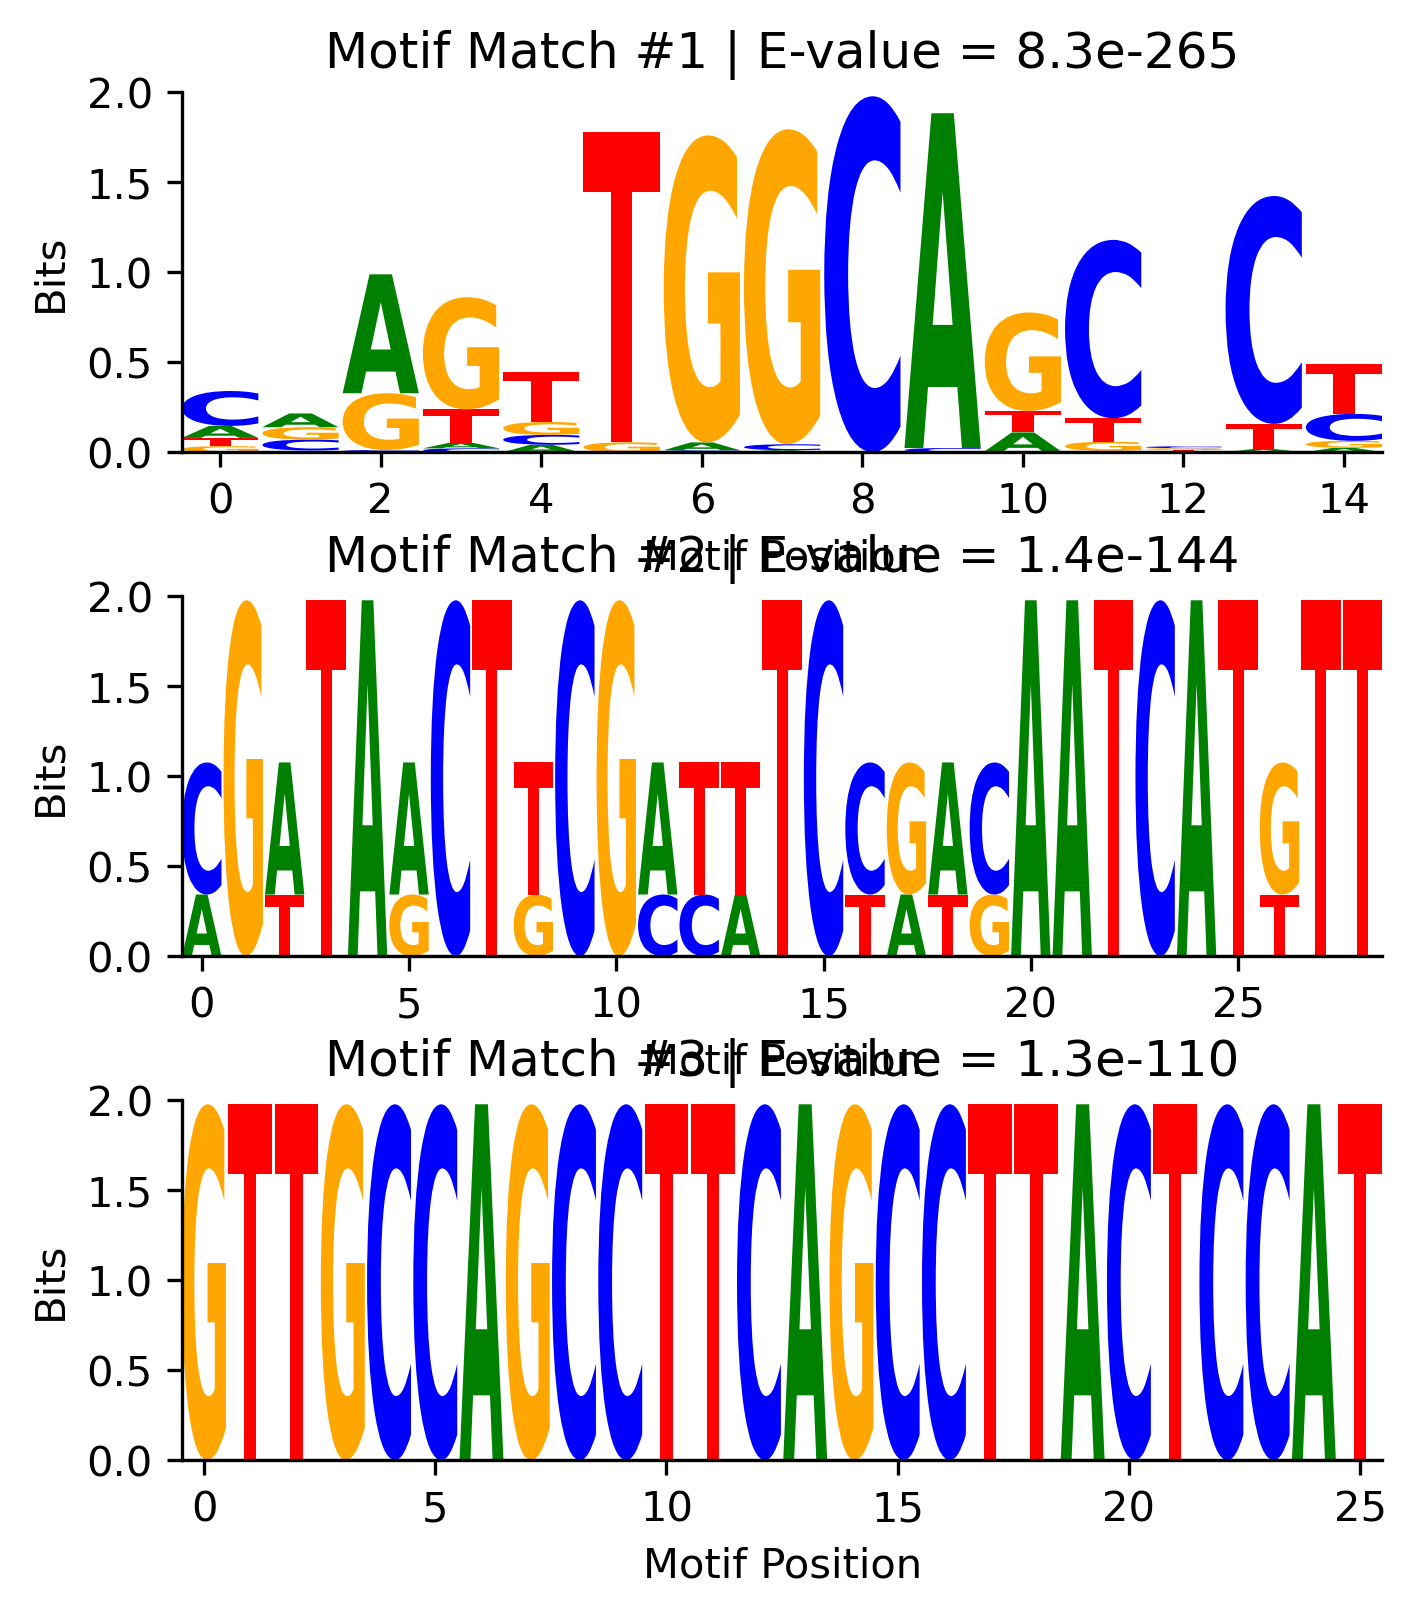

In [12]:
plot_matches(Trem_meme_file)

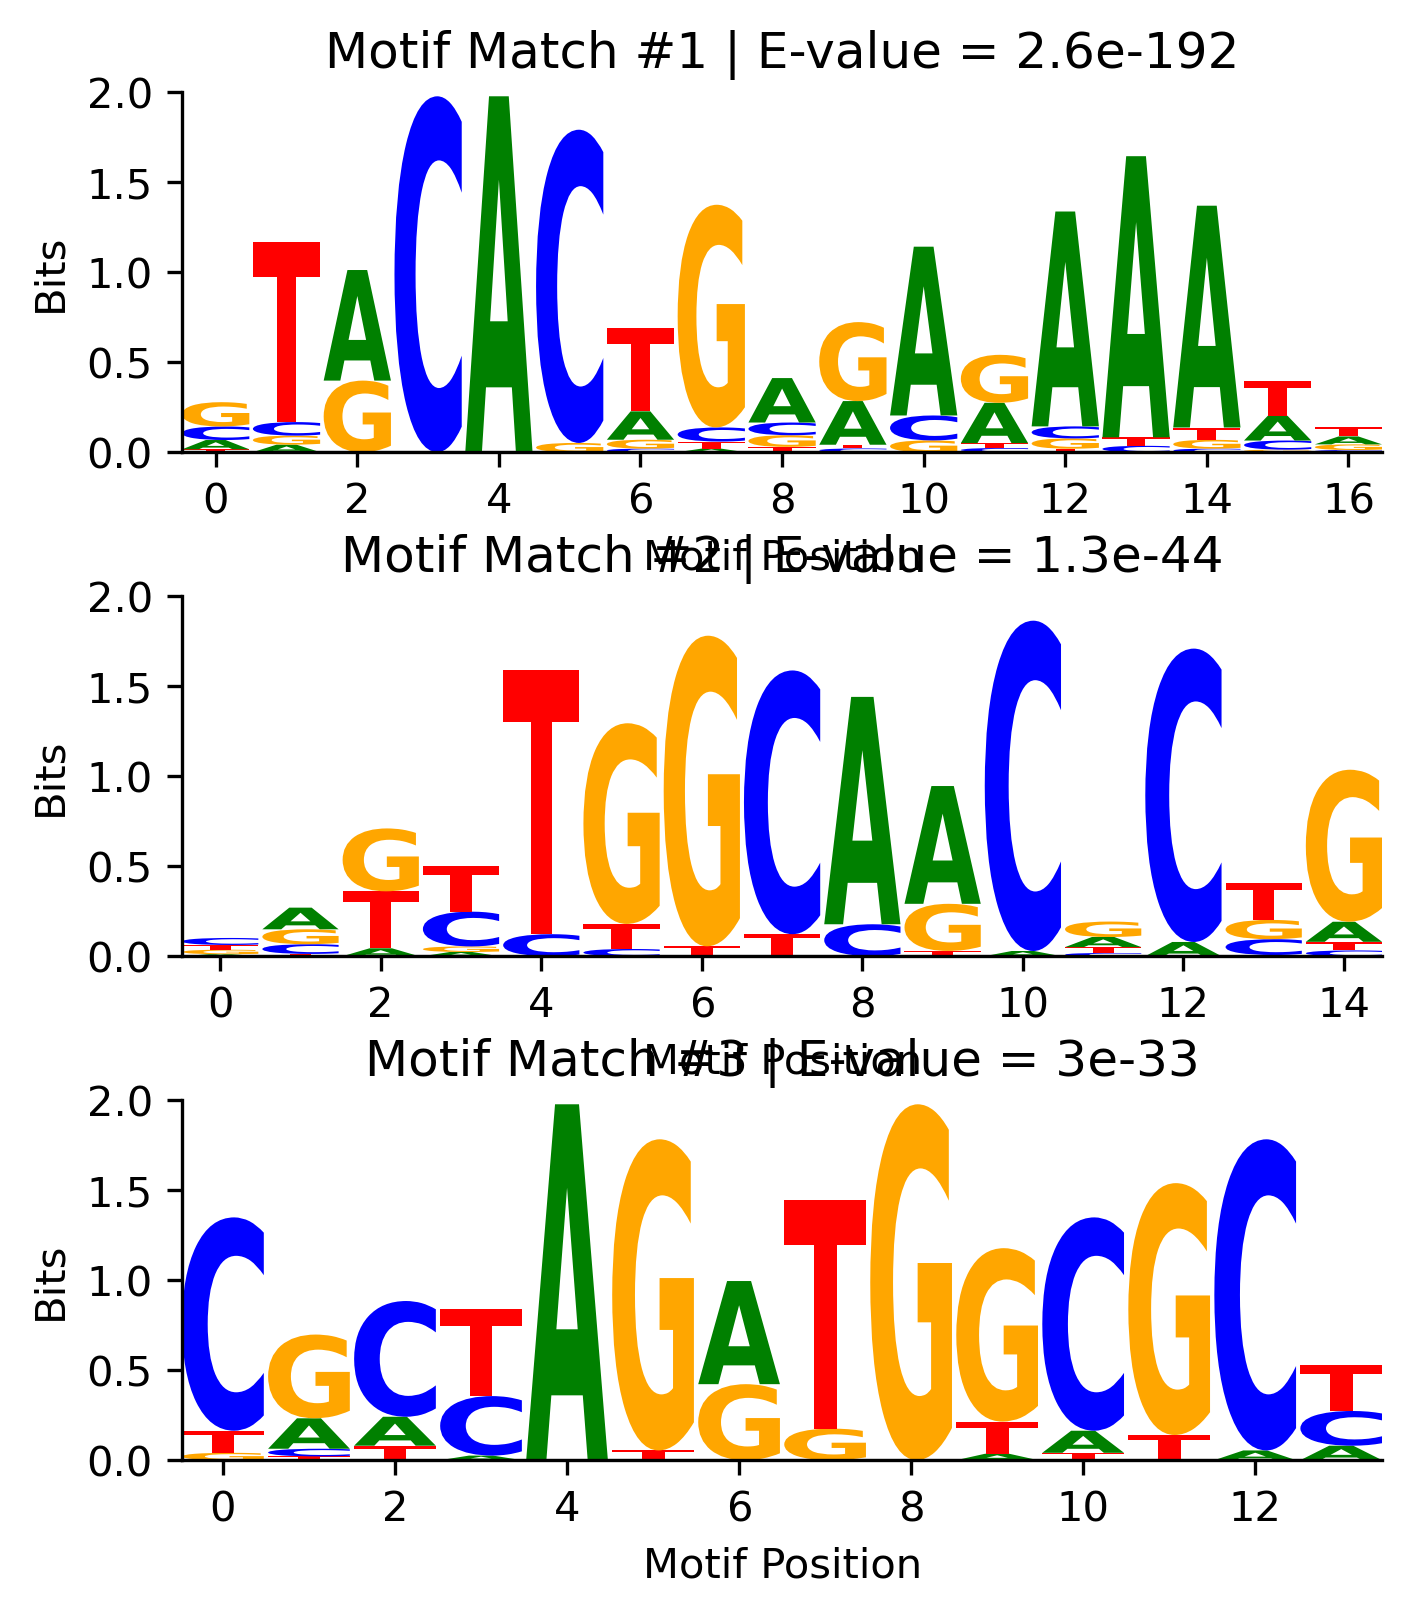

In [13]:
plot_matches(CG4854_meme_file, rc=True)

In [14]:
import matplotlib.pyplot as plt

def plot_protein_domains(
    length,
    domains,
    ax,
    figsize=(10, 2),
    title="Protein domain architecture",
    domain_height=0.4
):
    
    ax.hlines(0, 1, length, color="black", lw=2)

    for d in domains:
        if len(d) == 3:
            name, start, end = d
            color = "#8da0cb"
        elif len(d) == 4:
            name, start, end, color = d
        else:
            raise ValueError("Each domain must be (name, start, end[, color])")

        ax.barh(
            y=0,
            width=end - start + 1,
            left=start,
            height=domain_height,
            color=color,
            edgecolor="black",
            zorder=4
        )

        ax.text(
            (start + end) / 2,
            0.4,
            name,
            ha="center",
            va="center",
            fontsize=7
        )

    for name, spine in ax.spines.items():
        spine.set_visible(name == "bottom")
    
    if 'Trem' not in title:
        ax.xaxis.set_tick_params(labelbottom=False)

    ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([])
    if 'Trem' in title: ax.set_xlabel("Amino acid position")
    ax.set_title(title, fontsize=12, y=1.2)


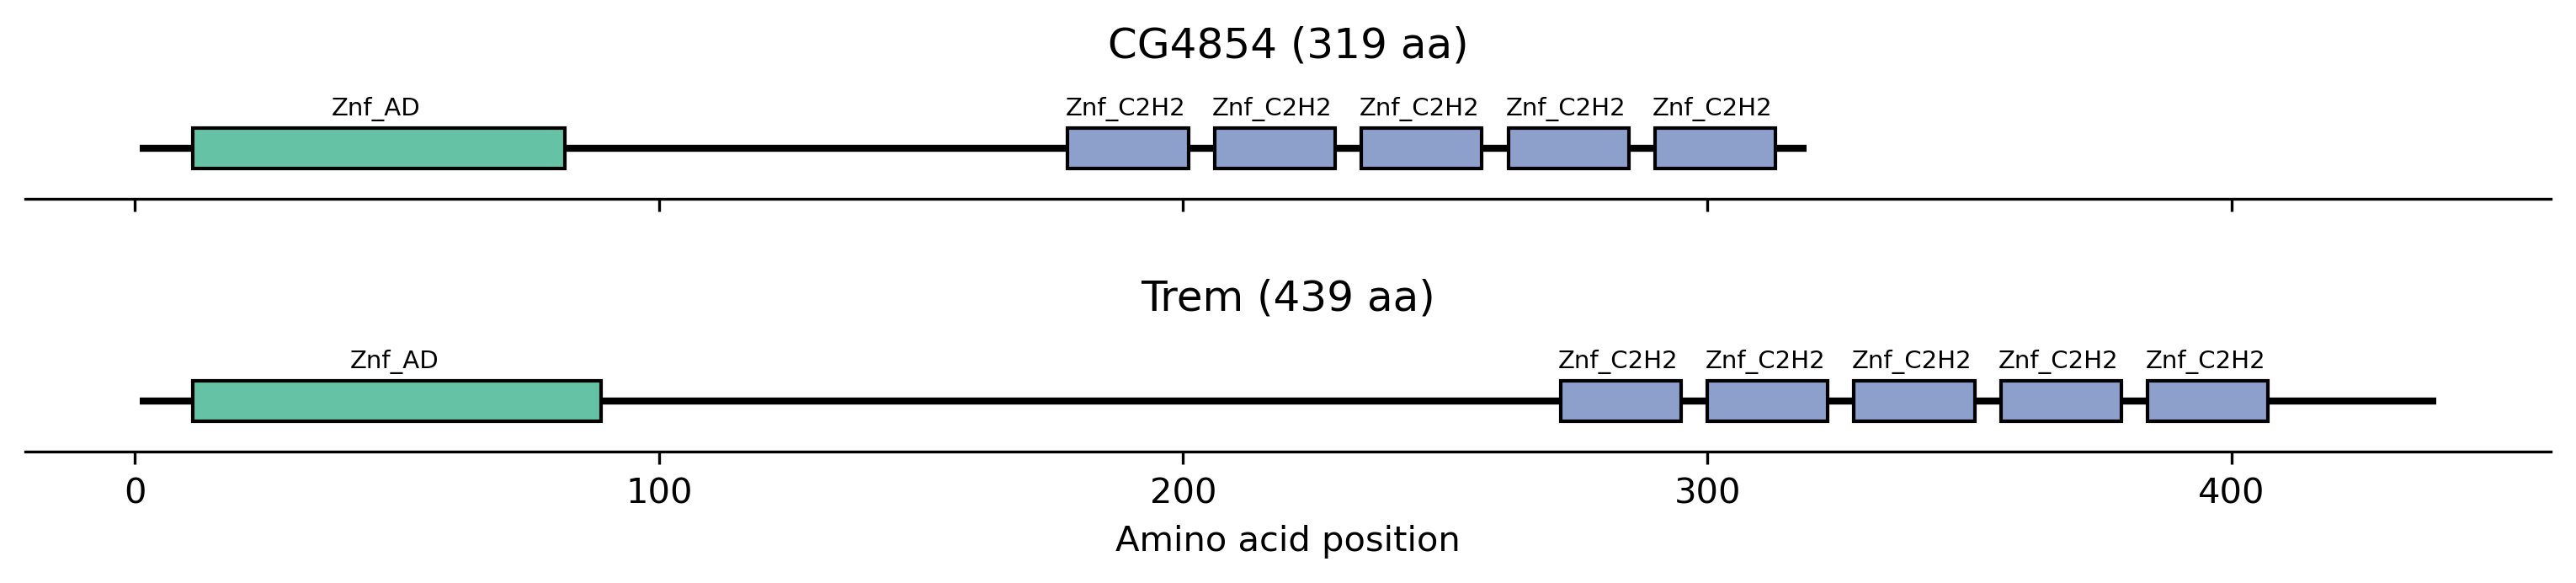

In [15]:
trem_protein_length = 439
trem_domains = [
    ("Znf_AD", 11, 88, "#66c2a5"),
    ("Znf_C2H2", 272, 294, "#8da0cb"),
    ("Znf_C2H2", 300, 322, "#8da0cb"),
    ("Znf_C2H2", 328, 350, "#8da0cb"),
    ("Znf_C2H2", 356, 378, "#8da0cb"),
    ("Znf_C2H2", 384, 406, "#8da0cb"),
]

CG4854_protein_length = 319
CG4854_domains = [
    ("Znf_AD", 11, 81, "#66c2a5"),
    ("Znf_C2H2", 178, 200, "#8da0cb"),
    ("Znf_C2H2", 206, 228, "#8da0cb"),
    ("Znf_C2H2", 234, 256, "#8da0cb"),
    ("Znf_C2H2", 262, 284, "#8da0cb"),
    ("Znf_C2H2", 290, 312, "#8da0cb"),
]

fig, axs = init_subplots_exact(2,2, dpi=300, y_ratios=[0.1, 0.1], x_ratios=[2.5], yspace=2.5, sharex=True)
plot_protein_domains(CG4854_protein_length, CG4854_domains, ax=axs[0], title=f"CG4854 ({CG4854_protein_length} aa)")
plot_protein_domains(trem_protein_length, trem_domains, ax=axs[1], title=f"Trem ({trem_protein_length} aa)")


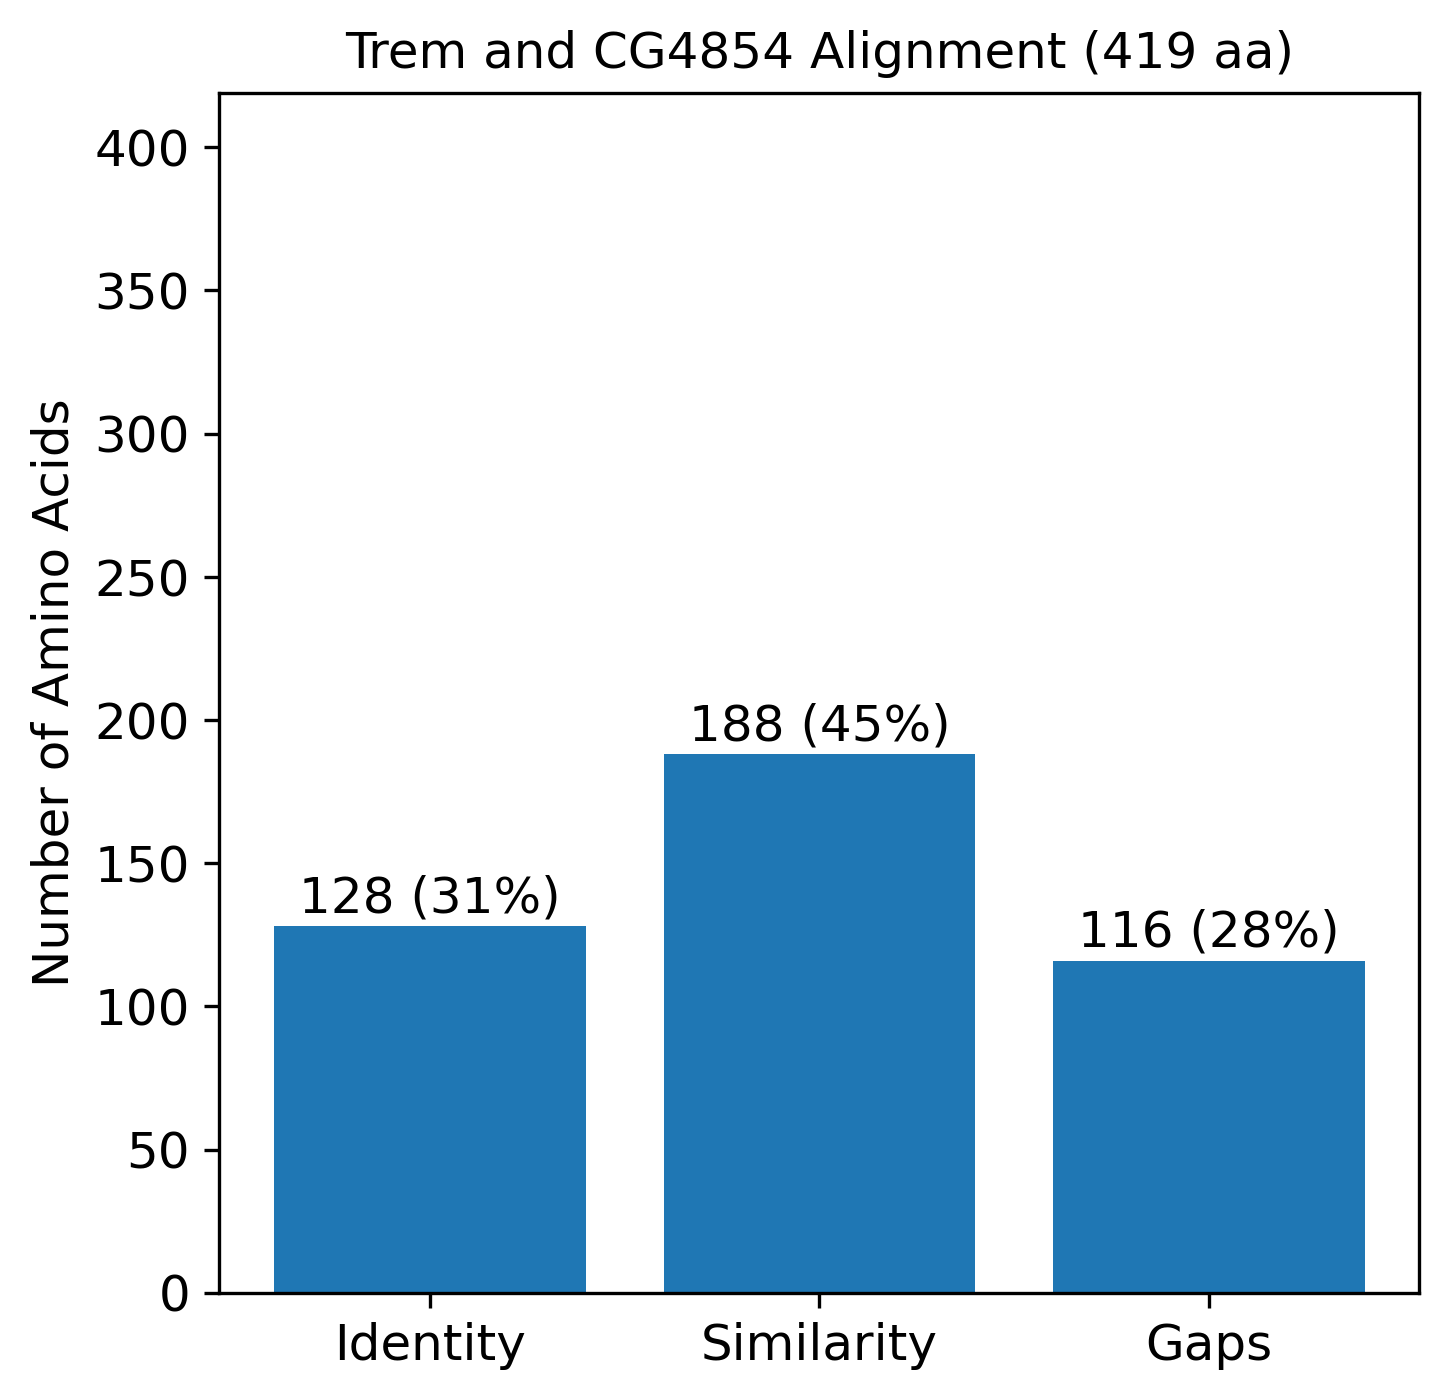

In [16]:
# stats obtained from https://www.flyrnai.org/cgi-bin/DRSC_prot_align.pl?geneid1=42392&geneid2=42391 

import matplotlib.pyplot as plt

plt.rcParams['font.size'] = '12'
labels = ['Identity', 'Similarity', 'Gaps']
values = [128, 188, 116]


fig, ax = init_subplots_exact(1,1,dpi=300)
plt.bar(labels, values)

for i, v in enumerate(values):
    plt.text(i, v + 5, f'{v} ({v/419:.0%})', ha='center')

plt.ylim([0, 419])
plt.ylabel('Number of Amino Acids')
plt.title('Trem and CG4854 Alignment (419 aa)', fontsize=12)
plt.show()


## Analyze Trem and CG4854 Peaks

In [17]:
def process_peak_df(df):
    new_cols = [
        # replicate 1 peaks
        "chrom",
        "chromStart",
        "chromEnd",
        "name",
        "score",
        "strand",
        "signalValue",
        "pValue",
        "qValue",
        "summit",
        "localIDR",
        "globalIDR",
        "rep1_chromStart",
        "rep1_chromEnd",
        "rep1_signalValue",
        "rep1_summit",
        "rep2_chromStart",
        "rep2_chromEnd",
        "rep2_signalValue",
        "rep2_summit"
    ]
    df.columns = new_cols
    return df


In [18]:
idr_peaks_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/chip/0_CHIP_motif_8_candidates/idr_peaks/"

trem_peaks = pd.read_csv(f"{idr_peaks_dir}/Trem_IDR.txt", sep='\t', header=None)
CG_peaks = pd.read_csv(f"{idr_peaks_dir}/CG4854_IDR.txt", sep='\t', header=None)

Trem_peaks = process_peak_df(trem_peaks)
CG4854_peaks = process_peak_df(CG_peaks)

In [19]:
# get all IDR thresholded peaks using global FDR of 0.05
IDR_THRESHOLD=-1*np.log10(0.05)
reproducible_Trem = Trem_peaks[Trem_peaks['globalIDR'] > IDR_THRESHOLD].query('~chrom.str.contains("_")')
reproducible_CG4854 = CG4854_peaks[CG4854_peaks['globalIDR'] > IDR_THRESHOLD].query('~chrom.str.contains("_")')
# this gets exact position of summit
reproducible_Trem['peak'] = reproducible_Trem['chromStart'] + reproducible_Trem['summit']
reproducible_CG4854['peak'] = reproducible_CG4854['chromStart'] + reproducible_CG4854['summit']

In [20]:
len(reproducible_Trem), len(reproducible_CG4854)

(2581, 1044)

In [21]:
def make_final_df(df, FACTOR2BBI, PEAK_RADIUS=250):
    """
    Creates coordinates of peaks relative to summit. Control is random region 20,000 bp to the left.
    """
    result = pd.DataFrame({
        'chrom': df.chrom,
        'start': df.peak - PEAK_RADIUS,
        'end': df.peak + PEAK_RADIUS
    })
    # random control
    for k, v in FACTOR2BBI.items():
        bbio = bbi.open(v)
        result[k] = bbio.stackup(result['chrom'], result['start'], result['end'], bins = 1)
        result[k+'_control'] = bbio.stackup(result['chrom'], result['start'] - 20000, result['end'] - 20000, bins = 1)
    return result

## Get final peak set for both Trem and CG4854

In [22]:
import bbi

root_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/chip/0_CHIP_motif_8_candidates/"

SAMPLES = pd.read_csv(f"{root_dir}/samples.csv").set_index("sample_id")
IP_SAMPLES = SAMPLES[SAMPLES['type']=='IP']
FACTORS = IP_SAMPLES['factor'].unique()

FACTOR2BBI = dict()
for f in FACTORS:
    for k in list(IP_SAMPLES[IP_SAMPLES['factor']==f].index):
        FACTOR2BBI[k] = f"/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/chip/0_CHIP_motif_8_candidates/bigwigs/{k}.bw"

final_Trem_df = make_final_df(reproducible_Trem, FACTOR2BBI)
final_CG4854_df = make_final_df(reproducible_CG4854, FACTOR2BBI)

### Peak overlap

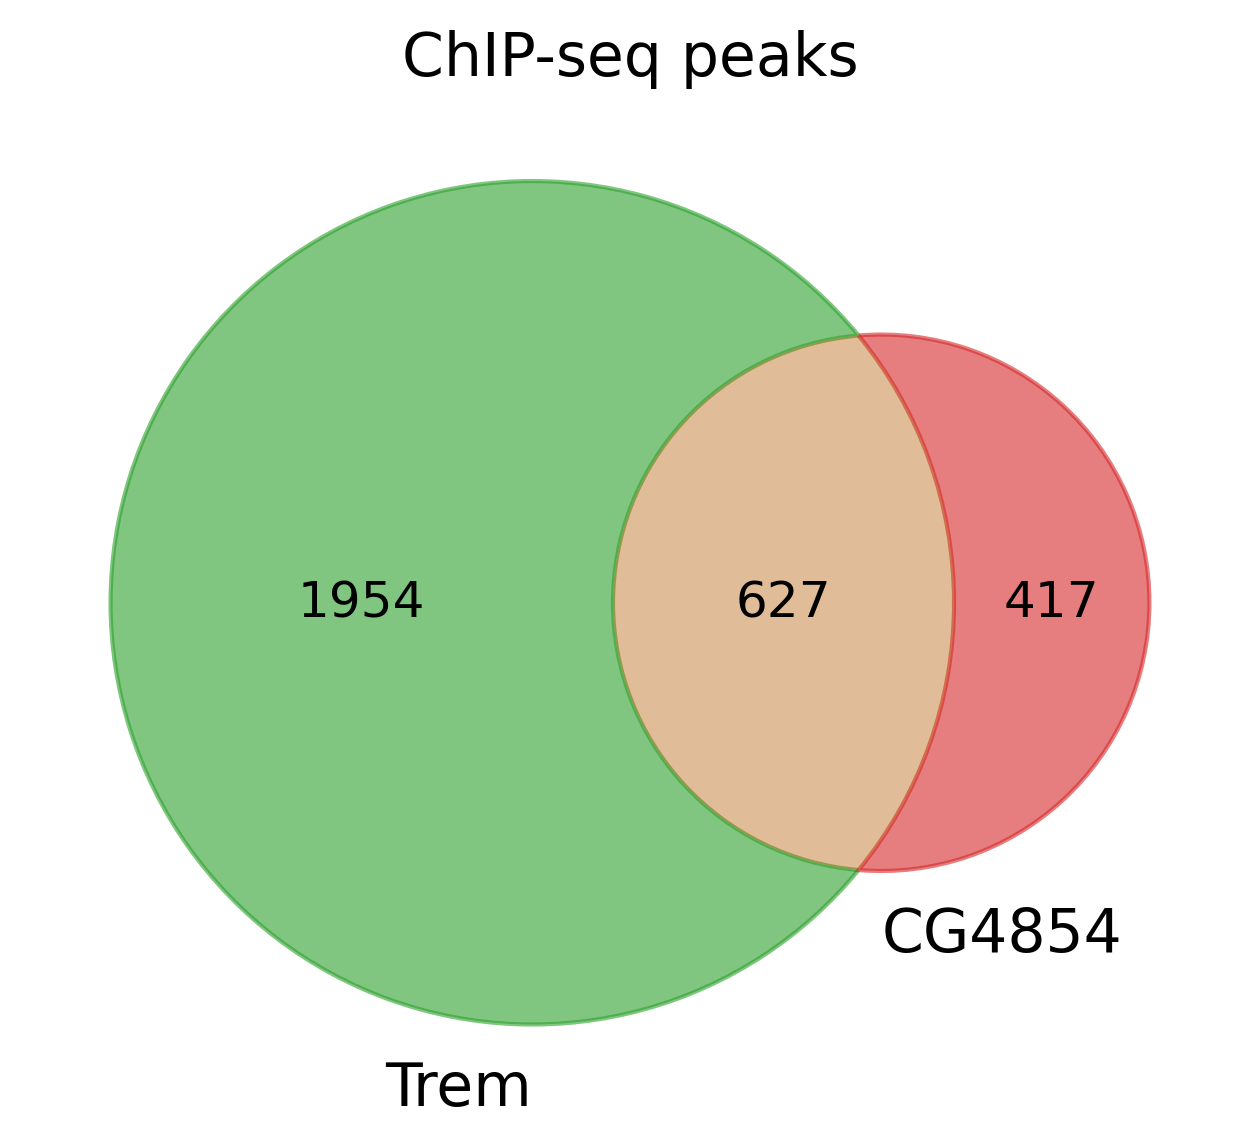

In [23]:
from matplotlib_venn import venn2
import matplotlib.pyplot as plt
import pybedtools

a = pybedtools.BedTool.from_dataframe(final_Trem_df[['chrom', 'start', 'end']]).sort()
b = pybedtools.BedTool.from_dataframe(final_CG4854_df[['chrom', 'start', 'end']]).sort()

# find all intervals in A that intersect with B and then merge overlapping/redundant intervals
overlap = a.intersect(b).merge()
overlap_count = overlap.count()

# Counts of each set
count_a = a.count()
count_b = b.count()

# Fractions
frac_a = overlap_count / count_a
frac_b = overlap_count / count_b

# Unique counts
A_only = count_a - overlap_count
B_only = count_b - overlap_count

fig, ax = init_subplots_exact(1,1,dpi=300)
v = venn2(subsets=(A_only, B_only, overlap_count), set_labels=('Trem', 'CG4854'))

v.get_patch_by_id('10').set_color("#2ca02c")  # A only
v.get_patch_by_id('01').set_color("#d62728")  # B only
for patch in ['10','01']:
    v.get_patch_by_id(patch).set_alpha(0.6)
    
v.get_label_by_id('10').set_text(f"{A_only}")
v.get_label_by_id('01').set_text(f"{B_only}")
v.get_label_by_id('11').set_text(f"{overlap_count}")
# 
plt.title("ChIP-seq peaks")
# fig.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/CG4854_Trem_venn_diagram.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

### Peak overlap with all boundaries (n=7311)

In [24]:
boundaries_df = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_nc14_boundaries_df.bound_score_gt_1.csv')
boundaries_df = boundaries_df.drop_duplicates(['chrom', 'start', 'end'])

model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu'

TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

non_bound_df = pd.concat([TRAIN_df, VAL_df, TEST_df]).reset_index(drop=True).query('boundary == 0').rename(columns={"demeaned_ins_score_1": "demeaned_ins_score"})

In [25]:
def get_overlap_a_in_b(a, b, complement=False):
    df1 = a
    df2 = b
    
    bed1 = pybedtools.BedTool.from_dataframe(df1[['chrom', 'start', 'end']])
    bed2 = pybedtools.BedTool.from_dataframe(df2[['chrom', 'start', 'end']])
    
    n1 = bed1.count()
    # if complement == False, get all overlaps; otherwise get all in bed1 not in bed2
    if complement == False: overlap = bed1.intersect(bed2, u=True)
    else: overlap = bed1.intersect(bed2, v=True)
    overlap_1in2 = overlap.count()
    pct_1in2 = overlap_1in2 / n1 * 100
    
    return pct_1in2, overlap.to_dataframe()
    
def get_peak_insulation_df(peak_df, ins_score_df, bound_df=None):
    """
    Get overlap between 500 bp peaks and 200 bp bin.
    Assign the highest insulation value to the peak.
    """
    bt_500 = pybedtools.BedTool.from_dataframe(peak_df)
    bt_200 = pybedtools.BedTool.from_dataframe(ins_score_df)

    # report the original entries from both a and b, plus the number of overlapping base pairs.
    inter = bt_500.intersect(bt_200, wo=True)
    df_inter = inter.to_dataframe(
        names=[
            "chrom_500", "start_500", "end_500",
            "chrom_200", "start_200", "end_200", "ins_score",
            "demeaned_ins_score", "overlap_bp"
        ]
    )
    display(df_inter.head())
    df_inter["demeaned_ins_score"] = pd.to_numeric(df_inter["demeaned_ins_score"].replace(".", pd.NA), errors="coerce")
    df_inter = df_inter.query('~demeaned_ins_score.isnull()')

    # if there is a boundary for overlapping (which in our case is always the case)
    if bound_df is not None:
        df_inter =  df_inter.merge(
            bound_df,
            left_on=["chrom_200", "start_200", "end_200"],
            right_on=["chrom", "start", "end"],
        )
    # keep lowest insulation to peak
    df_min = (
        df_inter
        .sort_values("demeaned_ins_score", ascending=True)
        .drop_duplicates(subset=["chrom_500","start_500","end_500"], keep="first")
    )
    return df_min

In [26]:
# get_overlap_a_in_b(final_CG4854_df, final_Trem_df)
Trem_in_bound_pct, Trem_in_bound = get_overlap_a_in_b(final_Trem_df, boundaries_df)
Trem_not_in_bound_pct, Trem_not_in_bound = get_overlap_a_in_b(final_Trem_df, boundaries_df, complement=True)
print('Trem', Trem_in_bound_pct, Trem_not_in_bound_pct)

CG4854_in_bound_pct, CG4854_in_bound = get_overlap_a_in_b(final_CG4854_df, boundaries_df)
CG4854_not_in_bound_pct, CG4854_not_in_bound = get_overlap_a_in_b(final_CG4854_df, boundaries_df, complement=True)
print('CG4854', CG4854_in_bound_pct, CG4854_not_in_bound_pct)

Trem 46.222394420767145 53.777605579232855
CG4854 30.938697318007662 69.06130268199234


In [27]:
from tqdm import tqdm

def permutation_test_peaks_overlap_boundaries(final_peak_df, factor, n_perm=1000):
    peaks = pybedtools.BedTool.from_dataframe(final_peak_df[["chrom", "start", "end"]])
    insulators = pybedtools.BedTool.from_dataframe(boundaries_df[["chrom", "start", "end"]])
    genome = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/scripts/dm6.chrom.sizes"
    blacklist = pybedtools.BedTool("/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/dm6-blacklist.v2.bed")
    
    observed = peaks.intersect(insulators, u=True).count()
    total_peaks = peaks.count()
    
    print(f"Observed promoter peaks: {observed}/{total_peaks}")
    
    null_counts = []
    SEED = 12345
    
    for i in tqdm(range(n_perm)):
        shuffled = peaks.shuffle(
            g=genome,
            excl=blacklist.fn,
            chrom=True,
            seed = SEED+i
        )
        c = shuffled.intersect(insulators, u=True).count()
        null_counts.append(c)
    
    null_counts = np.array(null_counts)

    mean_null = null_counts.mean()
    fold_enrichment = observed / mean_null
    
    print("Mean null overlaps:", mean_null)
    print("Fold enrichment:", fold_enrichment)
    
    p_value = (np.sum(null_counts >= observed) + 1) / (n_perm + 1)
    print("Empirical p-value:", p_value)
    
    fig, ax = init_subplots_exact(1,1,dpi=150)
    plt.hist(null_counts, bins=30, color="lightgray", edgecolor="black")
    plt.axvline(observed, color="red", linewidth=2, label="Observed")
    plt.xlabel("Number of promoter-overlapping peaks")
    plt.ylabel("Frequency")
    plt.title(f'{factor} Peaks')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return observed/total_peaks, p_value

Observed promoter peaks: 1193/2581


100%|██████████| 10000/10000 [03:17<00:00, 50.75it/s]
/tmp/ipykernel_3455521/1787637748.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Mean null overlaps: 100.0334
Fold enrichment: 11.92601671041872
Empirical p-value: 9.999000099990002e-05


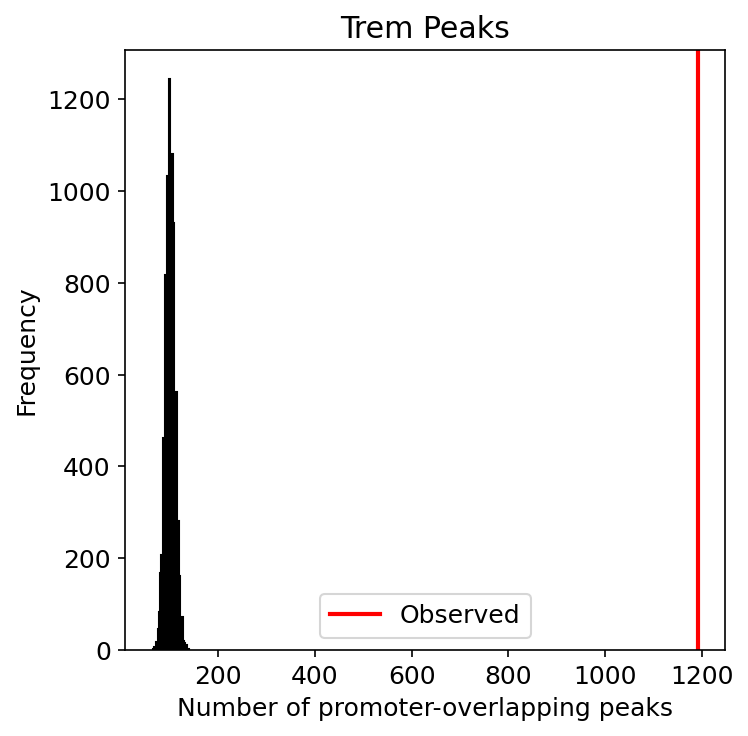

(0.46222394420767143, 9.999000099990002e-05)

In [43]:
permutation_test_peaks_overlap_boundaries(final_Trem_df, 'Trem', n_perm=10000)

Observed promoter peaks: 323/1044


100%|██████████| 10000/10000 [02:36<00:00, 63.78it/s]
/tmp/ipykernel_3455521/1787637748.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Mean null overlaps: 40.3008
Fold enrichment: 8.014729236144195
Empirical p-value: 9.999000099990002e-05


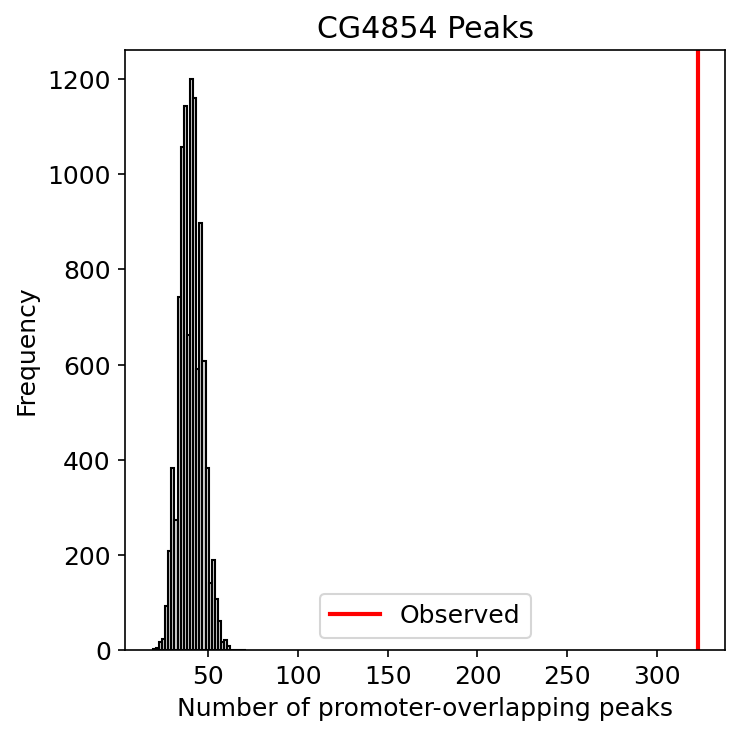

(0.30938697318007663, 9.999000099990002e-05)

In [44]:
permutation_test_peaks_overlap_boundaries(final_CG4854_df, 'CG4854', n_perm=10000)

In [28]:
len(Trem_in_bound), len(CG4854_in_bound), len(final_Trem_df), len(final_CG4854_df)

(1193, 323, 2581, 1044)

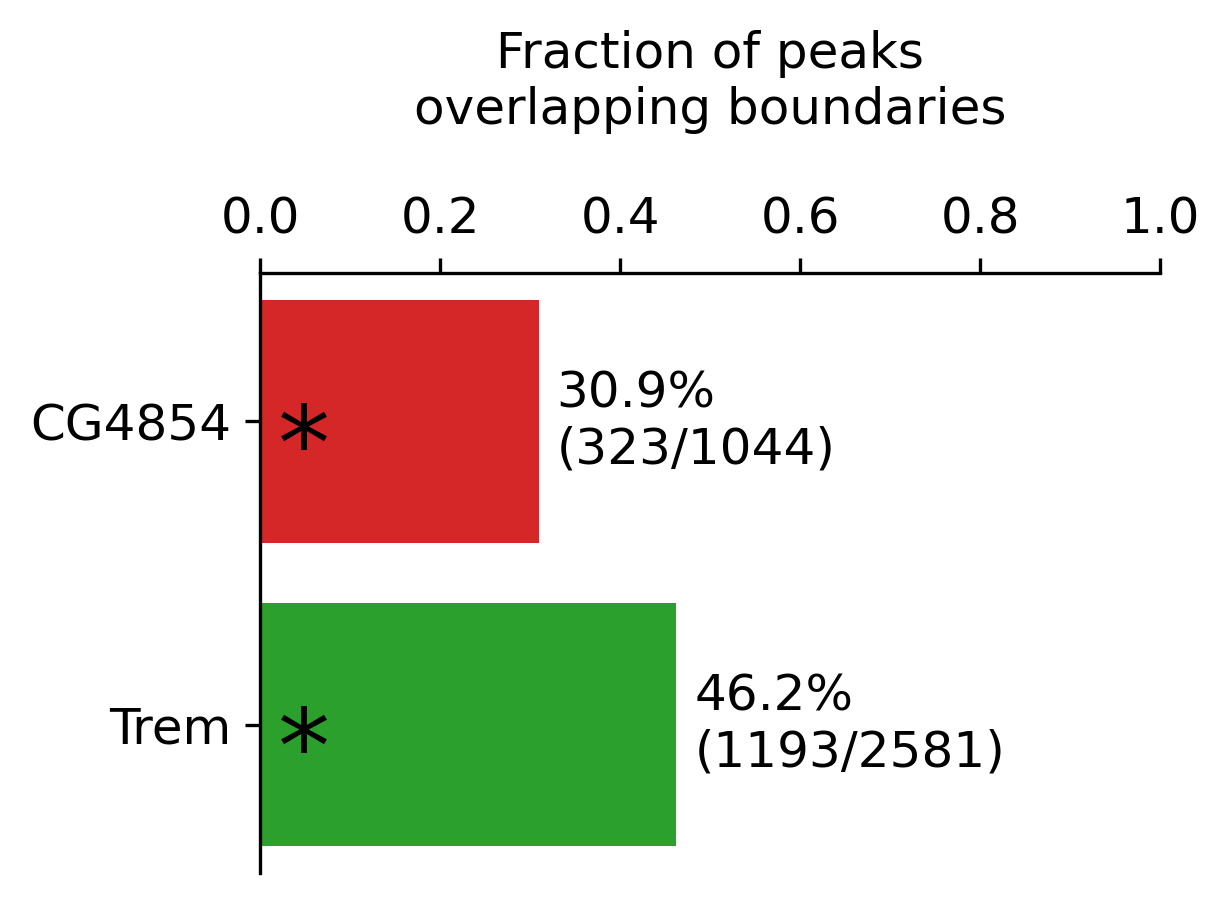

In [29]:
colors = ["#2ca02c", "#d62728"]

fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.5], x_ratios=[0.75])

labels = ["Trem", "CG4854"]
fractions = [len(Trem_in_bound)/len(final_Trem_df), len(CG4854_in_bound)/len(final_CG4854_df)]
counts = [(len(Trem_in_bound),len(final_Trem_df)), (len(CG4854_in_bound),len(final_CG4854_df))]
pvals = [9.999000099990002e-05, 9.999000099990002e-05]

ax.barh(labels, fractions, color=colors)
ax.set_xlim(0, 1)
ax.set_xlabel("Fraction of Peaks Overlapping Boundaries")

for i, (f, p, c) in enumerate(zip(fractions, pvals, counts)):
    ax.text(f + 0.02, i, f"{f:.1%}\n({c[0]}/{c[1]})", va="center")

for i, (f, p, c) in enumerate(zip(fractions, pvals, counts)):
    ax.text(0.02, i-0.1, f"*", va="center", fontsize=25)

ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_ticks_position('top')
ax.xaxis.set_label_position('top')
ax.set_xlabel("Fraction of peaks\noverlapping boundaries\n")
ax.set_xlim(0, 1)
# fig.savefig("plots/frac_overlap_boundaries.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

In [30]:
# get peaks that overlap and do not overlap with boundaries 

from domino.data.data import preprocess_data, process_bed_file_df

ins_score_df = process_bed_file_df('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_1kb.bed', 'ins_score')
# mean scaling
# "." means it's NaN
mean_scaling_window=10
ins_score_df["demeaned_ins_score"] = ins_score_df["ins_score"] - ins_score_df["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()

Trem_peaks_boundaries = get_peak_insulation_df(Trem_in_bound, ins_score_df, boundaries_df)
Trem_peaks_not_boundaries = get_peak_insulation_df(Trem_not_in_bound, ins_score_df)

CG4854_peaks_boundaries = get_peak_insulation_df(CG4854_in_bound, ins_score_df, boundaries_df)
CG4854_peaks_not_boundaries = get_peak_insulation_df(CG4854_not_in_bound, ins_score_df)

,chrom_500,start_500,end_500,chrom_200,start_200,end_200,ins_score,demeaned_ins_score,overlap_bp
0,chr2R,22411401,22411901,chr2R,22411401,22411600,0.129050,-0.3856965445336839,199
1,chr2R,22411401,22411901,chr2R,22411601,22411800,-0.233104,-0.7419214120932985,199
2,chr2R,22411401,22411901,chr2R,22411801,22412000,0.378219,-0.12270774443944277,100
3,chrX,10460431,10460931,chrX,10460401,10460600,-0.396324,-0.803727855728495,169
4,chrX,10460431,10460931,chrX,10460601,10460800,-0.849128,-1.3002159174176904,199


,chrom_500,start_500,end_500,chrom_200,start_200,end_200,ins_score,demeaned_ins_score,overlap_bp
0,chr3L,19861110,19861610,chr3L,19861001,19861200,0.3315242826938629,.,90
1,chr3L,19861110,19861610,chr3L,19861201,19861400,-0.0106876017525792,.,199
2,chr3L,19861110,19861610,chr3L,19861401,19861600,0.1074342355132103,.,199
3,chr3L,19861110,19861610,chr3L,19861601,19861800,0.2881388068199157,.,9
4,chr2L,2357183,2357683,chr2L,2357001,2357200,-0.2124665677547454,-0.2362906019247713,17


,chrom_500,start_500,end_500,chrom_200,start_200,end_200,ins_score,demeaned_ins_score,overlap_bp
0,chr2L,6612459,6612959,chr2L,6612401,6612600,0.276191,-0.3150212637015751,141
1,chr2L,6612459,6612959,chr2L,6612601,6612800,0.270828,-0.2976290356545222,199
2,chr2L,6612459,6612959,chr2L,6612801,6613000,0.585974,0.03402766656307943,158
3,chrX,4910138,4910638,chrX,4910001,4910200,0.761069,0.32548027521088063,62
4,chrX,4910138,4910638,chrX,4910201,4910400,0.559222,0.13170553956713044,199


,chrom_500,start_500,end_500,chrom_200,start_200,end_200,ins_score,demeaned_ins_score,overlap_bp
0,chr3L,19590367,19590867,chr3L,19590201,19590400,0.4008776545524597,0.08188785328751547,33
1,chr3L,19590367,19590867,chr3L,19590401,19590600,0.0479615926742553,-0.2685900366022471,199
2,chr3L,19590367,19590867,chr3L,19590601,19590800,0.0359134301543235,-0.2827341907790727,199
3,chr3L,19590367,19590867,chr3L,19590801,19591000,0.1872798949480056,-0.13322976089659175,66
4,chrX,2703629,2704129,chrX,2703601,2703800,0.2693545520305633,0.08880314744532239,171


## Micro-C KOs for CG4854 and Trem

In [31]:
import cooler 
import glob
import sys
sys.path.append('../../../python_modules/')
from generic_plotting_functions import *
from plot_motif8_kos import *
from helper_motif8_kos import *
from domino.data.data import preprocess_data, process_bed_file_df

CG_clr = cooler.Cooler('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/motif8_kos/downsampled/CG4854.mutant.mcool::resolutions/200')
Trem_clr = cooler.Cooler('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/motif8_kos/downsampled/Trem.mutant.mcool::resolutions/200')
WT_clr = cooler.Cooler('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/motif8_kos/downsampled/Dmel.WT.mcool::resolutions/200')


target2mcool = {
    'CG4854_KO': '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/motif8_kos/downsampled/CG4854.mutant.mcool',
    'Trem_KO': '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/motif8_kos/downsampled/Trem.mutant.mcool',
    'WT': '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/motif8_kos/downsampled/Dmel.WT.mcool'
}

target2bbi = dict()
target2bbi['Trem'] = bbi.open('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/run_all_chip_seq/bigwig/Trem.bw')
target2bbi['CG4854'] = bbi.open('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/run_all_chip_seq/bigwig/CG4854.bw')

In [32]:
ws = 1
mean_scaling_window=10
target2ins = dict()
for target in ['CG4854', 'WT', 'Trem']:
    file = glob.glob(f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/motif8_kos/*{target}*.window_size={ws}kb*.bed')
    assert(len(file) == 1)
    df = process_bed_file_df(file[0], 'ins_score')
    df["final_insulation_score"] = df["ins_score"] - df["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()
    df['chrom'] = df['chrom'].str.replace('Dmel.', '')
    target2ins[target] = df

combined_wt_ko_df = pd.DataFrame({
    'chrom': target2ins['WT'].chrom,
    'start': target2ins['WT'].start,
    'end': target2ins['WT'].end,
    'WT': target2ins['WT'].final_insulation_score,
    'CG4854_KO': target2ins['CG4854'].final_insulation_score,
    'Trem_KO': target2ins['Trem'].final_insulation_score,
})


# get all peaks that overlap boundaries and merge in the insulation values across all three conditions
Trem_bound_compare_df = pd.merge(Trem_peaks_boundaries, combined_wt_ko_df, left_on=['chrom_200', 'start_200', 'end_200'], right_on=['chrom', 'start', 'end'])
CG4854_bound_compare_df = pd.merge(CG4854_peaks_boundaries, combined_wt_ko_df, left_on=['chrom_200', 'start_200', 'end_200'], right_on=['chrom', 'start', 'end'])

In [33]:
condition2color = {
    'WT': 'gray',
    'CG4854_KO': '#d62728',
    'Trem_KO': '#2ca02c'
}
def boxplot_across_conditions(bound_compare_df, cols, title, ax, plot=True):
    
    plot_df = bound_compare_df[cols].dropna()
    from scipy.stats import ttest_rel
    stat, pval = ttest_rel(plot_df[cols[0]], plot_df[cols[1]])
    if plot:
        df_long = plot_df.melt(var_name="Condition", value_name="Insulation")
        sns.boxplot(x="Condition", y="Insulation", hue='Condition', palette=condition2color, data=df_long, showcaps=True, showfliers=False, ax=ax)
        ax.set_title(f'{title} (n={len(bound_compare_df)})\np = {pval:.2e}', fontsize=16)
    
    # WT always second (KO - WT)/WT (relative change)
    return pval, ((plot_df[cols[0]] - plot_df[cols[1]])/(plot_df[cols[1]])).median()


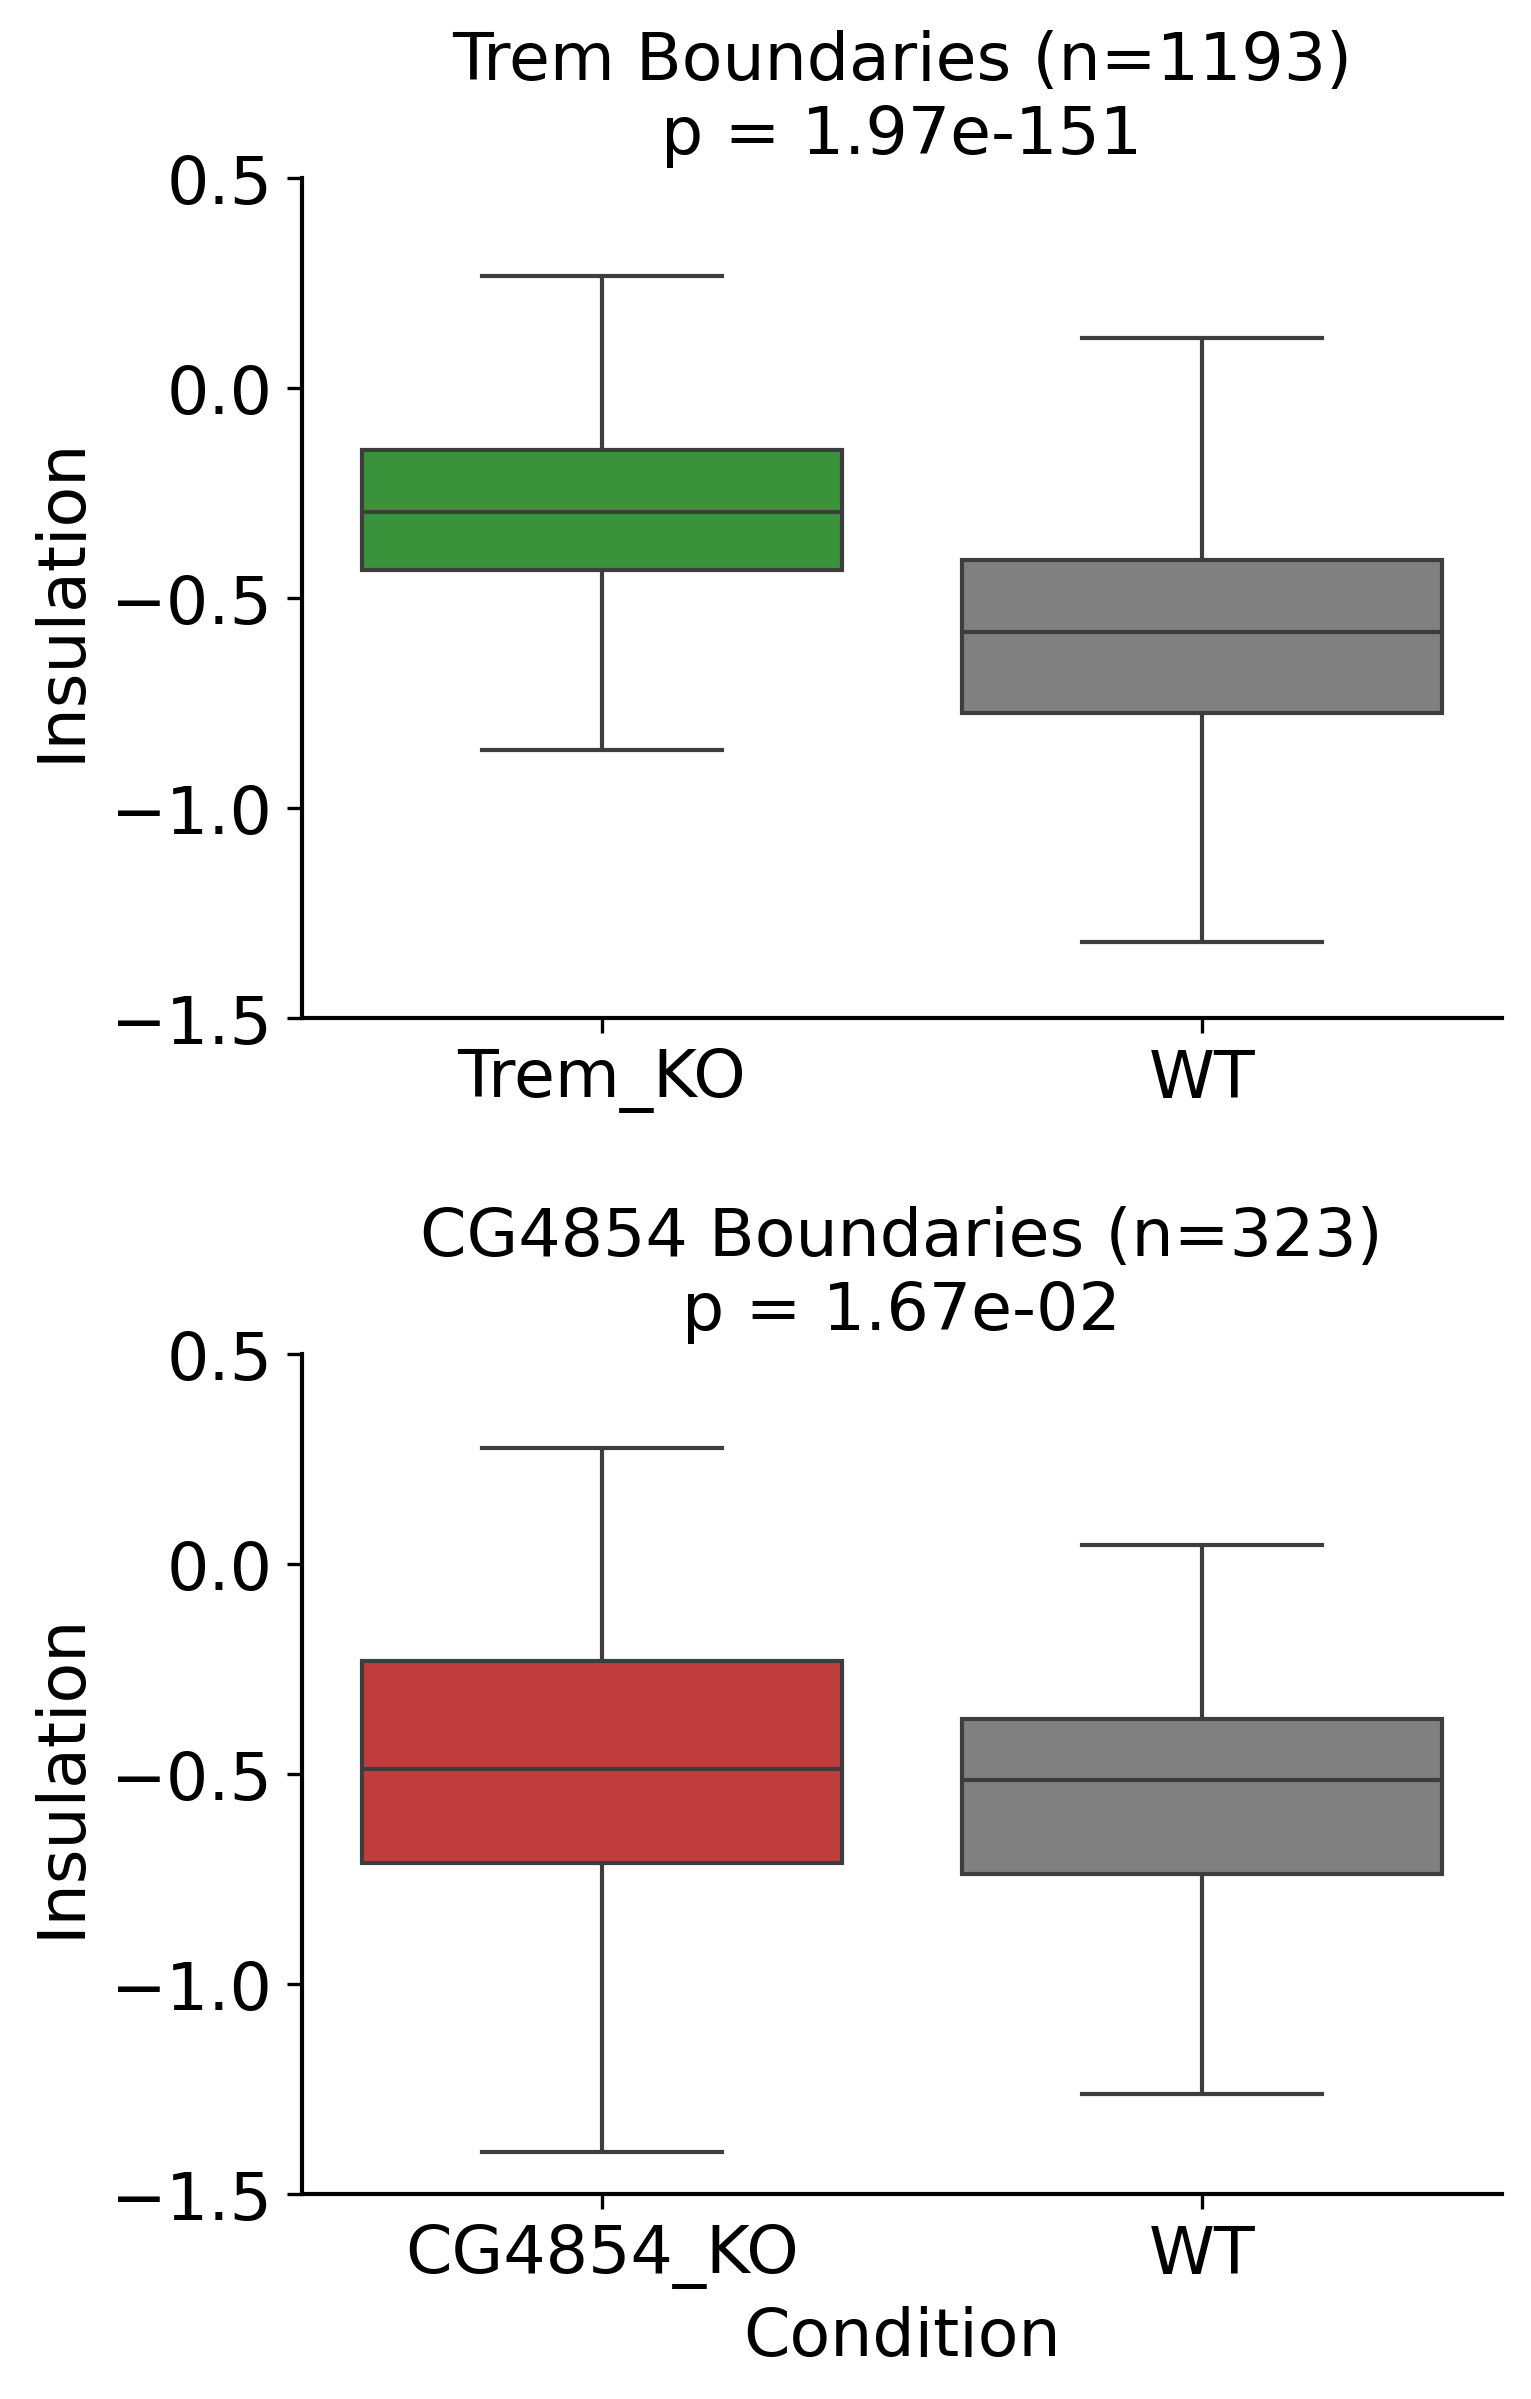

In [34]:
plt.rcParams['font.size'] = 16
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

fig, axs = init_subplots_exact(2, 2, dpi=300, yspace=1.4, y_ratios=[0.7]*2)

boxplot_across_conditions(Trem_bound_compare_df, ['Trem_KO', 'WT'], title='Trem Boundaries', ax=axs[0])
boxplot_across_conditions(CG4854_bound_compare_df, ['CG4854_KO', 'WT'], title='CG4854 Boundaries', ax=axs[1])

for ax in axs:
    ax.spines[['right', 'top']].set_visible(False)
    for spine in ['left', 'bottom']:  
        ax.spines[spine].set_color('black')  
        ax.spines[spine].set_linewidth(1)  # Decrease spine thickness
        
axs[0].set_xlabel("")

for ax in axs:
    ax.set_ylim([-1.5, 0.5])
# fig.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/KO_vs_WT_insulation_boxplots.pdf", format="pdf", dpi=300, bbox_inches='tight')

plt.show()


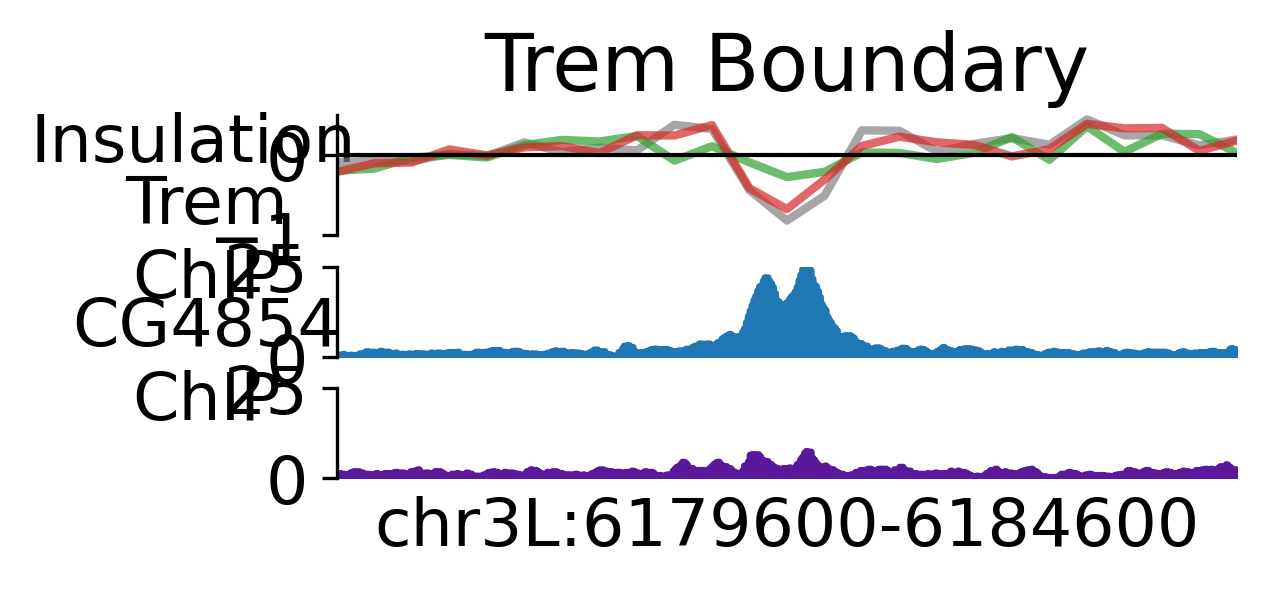

In [35]:
bound_of_interest = Trem_bound_compare_df.loc[[369]]

bin_radius=12

chrom, start, end = bound_of_interest.chrom_200.item(), bound_of_interest.start_200.item(), bound_of_interest.end_200.item()

boi_index = combined_wt_ko_df.query('chrom == @chrom and start == @start and end == @end').index[0]
plot_df = combined_wt_ko_df.iloc[boi_index-bin_radius:boi_index+bin_radius+1]

fig, axs = init_subplots_exact(3,3, dpi=300, y_ratios=[0.1, 0.075, 0.075], x_ratios=[0.75], yspace=1.35)

ax=axs[0]
for ycol in ['WT', 'Trem_KO', 'CG4854_KO']:
    sns.lineplot(plot_df, x='start', y=ycol, label=ycol, ax=axs[0], lw=2, alpha=0.7, color=condition2color[ycol])   
ax.set_ylabel('Insulation', rotation=0)
ax.set_xticks([])
ax.set_ylim([-1, 0.5])
ax.axhline(y=0, c='black', lw=1)
ax.set_xlabel(None)
ax.legend().set_visible(False)
ax.set_title('Trem Boundary')

# Trem 
ax=axs[1]
Trem_ChIP = target2bbi['Trem'].fetch(plot_df.chrom.unique()[0], plot_df.start.min()-1, plot_df.end.max())
ax.fill_between(np.arange(plot_df.start.min()-1, plot_df.end.max()), Trem_ChIP, color="#1f77b4", rasterized=True, lw=1.5)
ax.set_ylabel('Trem\nChIP', rotation=0)
ax.set_xlabel(None)
ax.set_xticks([])
ax.set_ylim([0, 25])

# CG4854
ax=axs[2]
CG4854_ChIP = target2bbi['CG4854'].fetch(plot_df.chrom.unique()[0], plot_df.start.min()-1, plot_df.end.max())
ax.fill_between(np.arange(plot_df.start.min()-1, plot_df.end.max()), CG4854_ChIP, color="#5a189a", rasterized=True, lw=1.5)
ax.set_ylabel('CG4854\nChIP', rotation=0)
ax.set_xlabel(f'{plot_df.chrom.unique()[0]}:{ plot_df.start.min()-1}-{plot_df.end.max()}')
ax.set_xticks([])
ax.set_ylim([0, 25])


for ax in axs:
    ax.set_xlim([plot_df.start.min()-1, plot_df.end.max()-200])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    
# fig.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/KO_plot_Trem_boundary.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

# ChIP-seq differences

In [36]:
# Get all boundaries with Motif-8 instance

TFMODISCO_WINDOW=600
out_folder = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/ism_report_1_cutoff//'
modisco_results = h5py.File(f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5","r")
metacluster = modisco_results['neg_patterns']
motif8_instances = pd.DataFrame({
    'idx': metacluster['pattern_6']['seqlets']['example_idx'],
    'start': metacluster['pattern_6']['seqlets']['start'],
    'end': metacluster['pattern_6']['seqlets']['end']
})
modisco_results.close()

fig2_bounds = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_nc14_boundaries_df.bound_score_gt_1.csv')
motif8_bound = fig2_bounds.loc[motif8_instances.idx].drop_duplicates(['chrom','start','end'])

In [37]:
boundaries_df['long_str'] = boundaries_df.chrom + ':' + boundaries_df.start.astype(str) + '-' + boundaries_df.end.astype(str)
boundaries_df['CG4854'] = target2bbi['CG4854'].stackup(boundaries_df.chrom, boundaries_df.start, boundaries_df.end, bins=1)
boundaries_df['Trem'] = target2bbi['Trem'].stackup(boundaries_df.chrom, boundaries_df.start, boundaries_df.end, bins=1)

# all motif
motif8_boundaries = motif8_bound.merge(boundaries_df, on=['chrom', 'start', 'end']).drop_duplicates(['chrom','start','end'])
motif8_strings = motif8_boundaries.long_str

no_motif8_boundaries = boundaries_df.query('~long_str.isin(@motif8_strings)').drop_duplicates(['chrom','start','end'])

model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

non_bound_df = pd.concat([TRAIN_df, VAL_df, TEST_df]).reset_index(drop=True).query('boundary == 0').rename(columns={"demeaned_ins_score_1": "demeaned_ins_score"}).sample(n=len(no_motif8_boundaries), random_state=10)
non_bound_df['CG4854'] =  target2bbi['CG4854'].stackup(non_bound_df.chrom, non_bound_df.start, non_bound_df.end, bins=1)
non_bound_df['Trem'] = target2bbi['Trem'].stackup(non_bound_df.chrom, non_bound_df.start, non_bound_df.end, bins=1)

print(len(boundaries_df), len(motif8_boundaries), len(no_motif8_boundaries))


7311 644 6667


In [38]:
from scipy.stats import mannwhitneyu
from itertools import combinations

def plot_col_across_groups(pb, pnb, control, col, ax, title):
    df1_plot = pb[[col]].copy()
    df1_plot["group"] = f"Motif-8 (n={len(df1_plot)})"
    
    df2_plot = pnb[[col]].copy()
    df2_plot["group"] = f"No Motif-8 (n={len(df2_plot)})"
    
    df3_plot = control[[col]].copy()
    df3_plot["group"] = f"Control (n={len(df3_plot)})"
    
    # Combine all three DataFrames
    df_all = pd.concat([df1_plot, df2_plot, df3_plot], ignore_index=True)

    plt.sca(ax)
    sns.boxplot(
        data=df_all,
        x="group",
        y=col,
        showfliers=False,
        # fliersize=1,
        ax=ax
        # flierprops=dict(marker='o', markersize=1, color='red', alpha=0.5),
    )
    ax.set_ylabel(f'{col} ChIP-seq')
    ax.set_xlabel('')
    plt.xticks(rotation=45)
    # ax.set_title(title)
    # ax.set_ylim([-0.5, 20])

    ax.spines[['right', 'top']].set_visible(False)
    for spine in ['left', 'bottom']:  
        ax.spines[spine].set_color('black')  
        ax.spines[spine].set_linewidth(1)  # Decrease spine thickness

    group_col = "group"
    value_col = col
    
    groups = df_all[group_col].unique()
    results = []
    
    for g1, g2 in combinations(groups, 2):
        x = df_all[df_all[group_col] == g1][value_col].dropna()
        y = df_all[df_all[group_col] == g2][value_col].dropna()
        
        # test if g1 > g2
        stat, p = mannwhitneyu(x, y, alternative='greater')
        
        results.append({
            "comparison": f"{g1} > {g2}",
            "U_stat": stat,
            "p_value": p
        })
    
    results_df = pd.DataFrame(results)
    display(results_df)

,comparison,U_stat,p_value
0,Motif-8 (n=644) > No Motif-8 (n=6667),3083860.0,2.825649e-75
1,Motif-8 (n=644) > Control (n=6667),3731033.0,6.129943e-211
2,No Motif-8 (n=6667) > Control (n=6667),27888535.5,1.425743e-143


,comparison,U_stat,p_value
0,Motif-8 (n=644) > No Motif-8 (n=6667),3288297.5,1.244358e-110
1,Motif-8 (n=644) > Control (n=6667),4022732.0,8.667290e-295
2,No Motif-8 (n=6667) > Control (n=6667),33016425.0,0.000000e+00


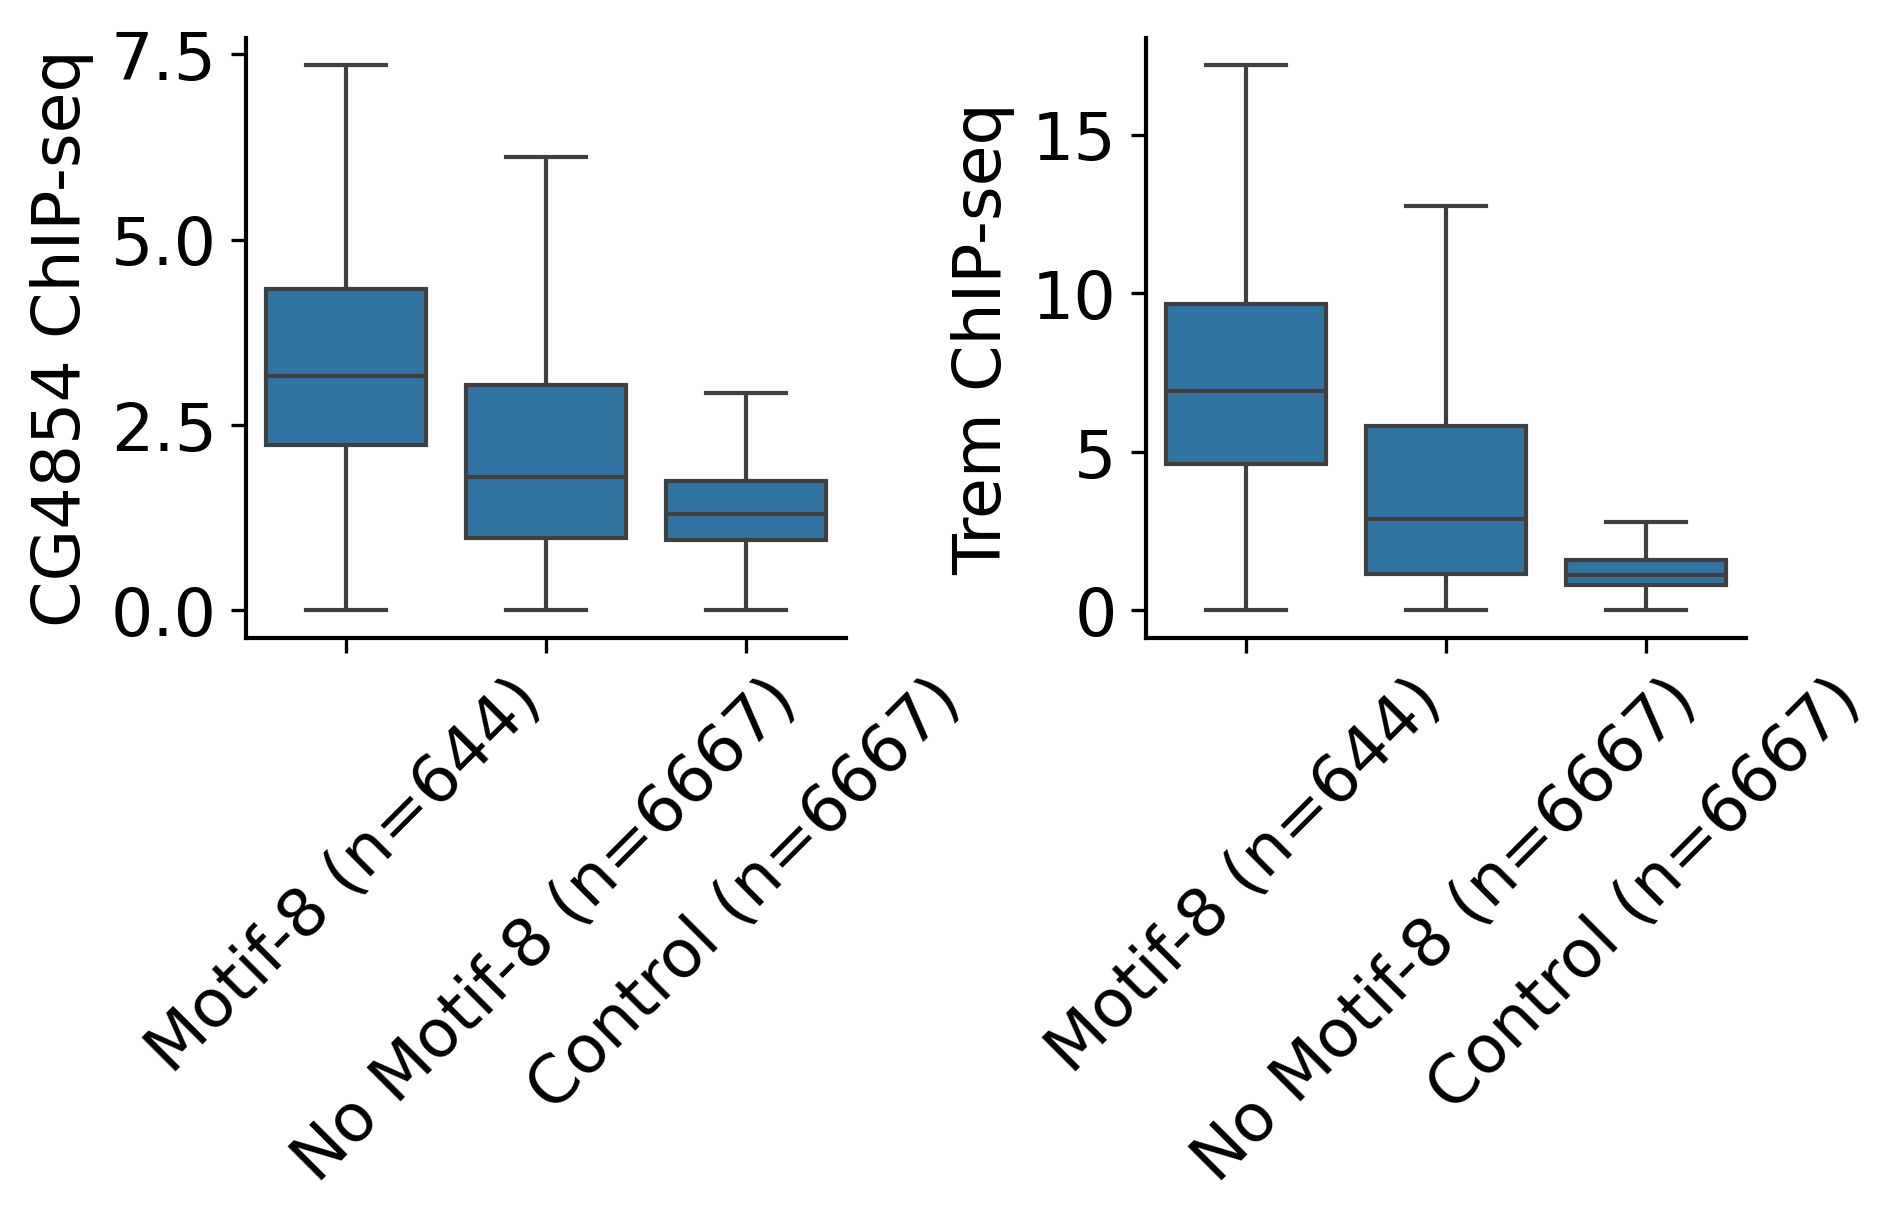

In [39]:
import seaborn as sns
fig, axs = init_subplots_exact(2,1,dpi=300, x_ratios=[0.5] * 2, y_ratios=[0.5], xspace=1.5)
plot_col_across_groups(motif8_boundaries, no_motif8_boundaries, non_bound_df, col='CG4854', ax=axs[0], title='CG4854')
plot_col_across_groups(motif8_boundaries, no_motif8_boundaries, non_bound_df, col='Trem', ax=axs[1], title='Trem')
# fig.savefig("plots/Trem_and_CG4854_across_groups_boxplots.pdf", format="pdf", dpi=300, bbox_inches='tight')


[ERROR:tab.py:300 -                query()] Reference sequence chr2R not found in index header.


chr2R:9954319-10005795


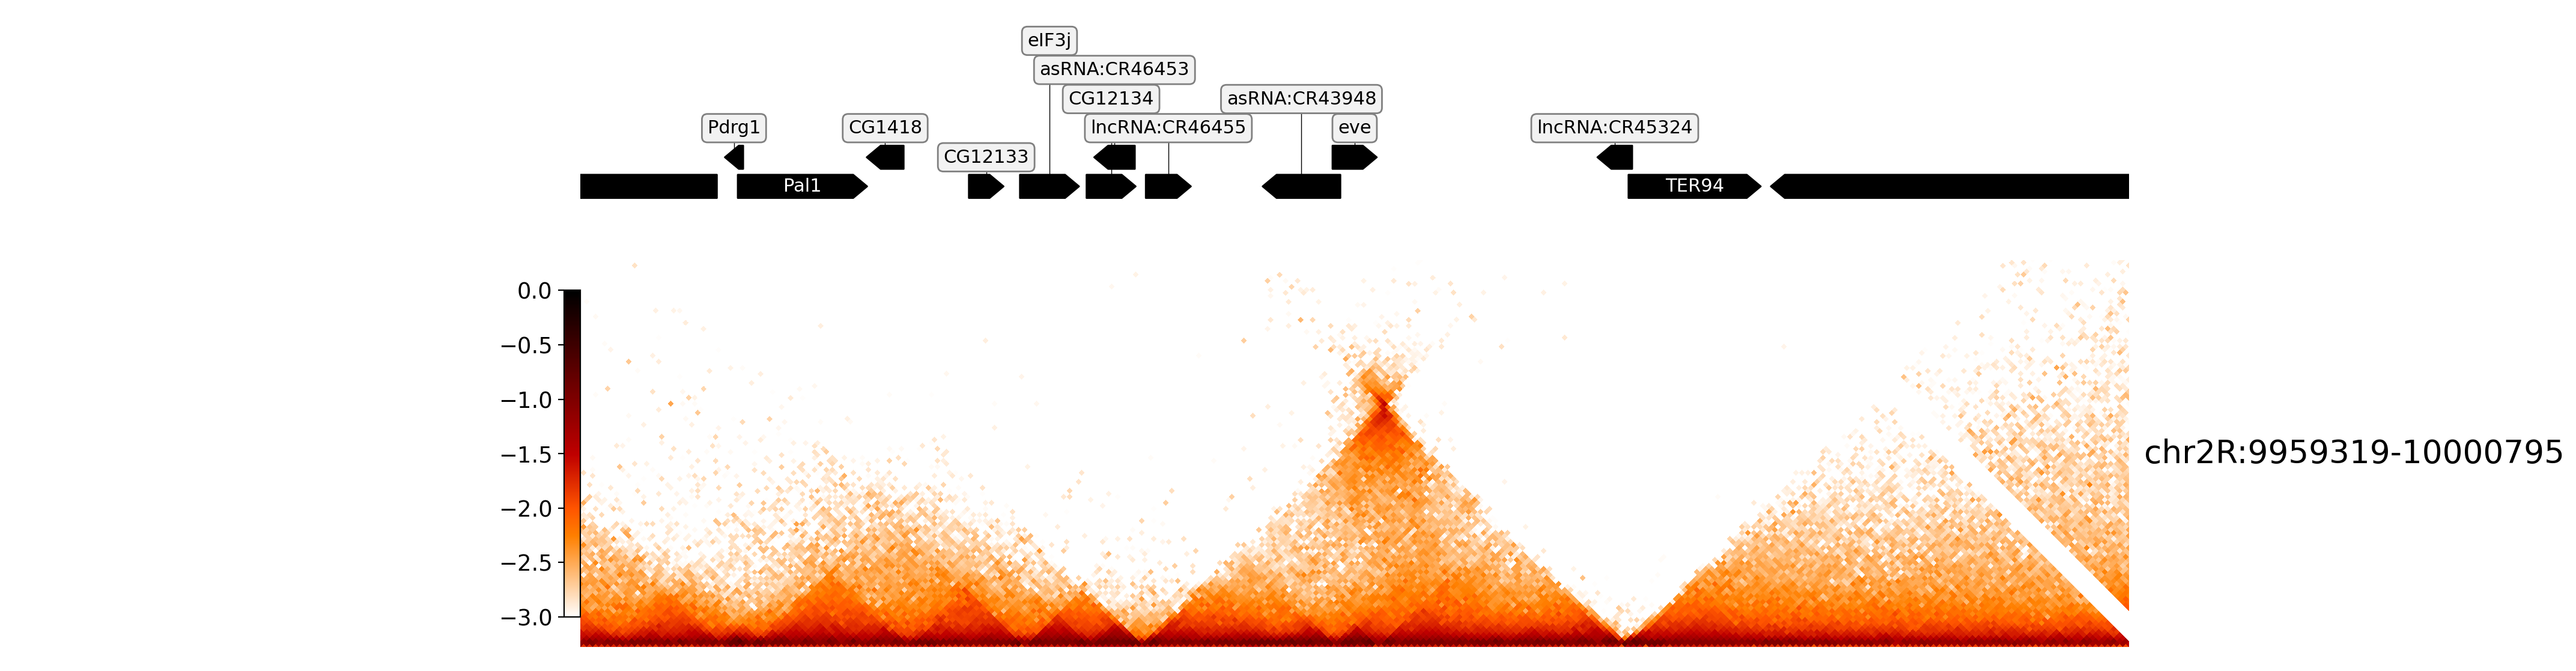

In [40]:
import coolbox
from coolbox.api import *

# matplotlib inline

loffset=25_000
roffset=25_000
HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=0.5, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3, 
    grid=False,
)
MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
chrom, start, end = "chr2R", 9979319, 9980795

frame = [
    coolbox.api.GTF('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/Drosophila_melanogaster.BDGP6.54.115.gtf',
                                                    row_filter="type == 'gene'", color="#000000"), 
    TrackHeight(4),
    coolbox.api.Spacer(1), 
    coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
    coolbox.api.HiCMat(f"{MCOOL_DATA_DIR}/new_nc14_embryo_merged_all_11.mcool", **HIC_KWARGS, title=f"{chrom}:{start-20_000}-{end + 20_000}"),
    coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),

]
from functools import reduce

frame = reduce(lambda x, y: x + y, frame)
print(f"{chrom}:{start-loffset}-{end + roffset}")
fig = frame.plot(f"{chrom}:{start-loffset}-{end + roffset}")
fig.set(facecolor="white")
# fig.savefig("plots/Trem_and_CG4854_example_loci.pdf", format="pdf", dpi=300, bbox_inches='tight')

display(fig)

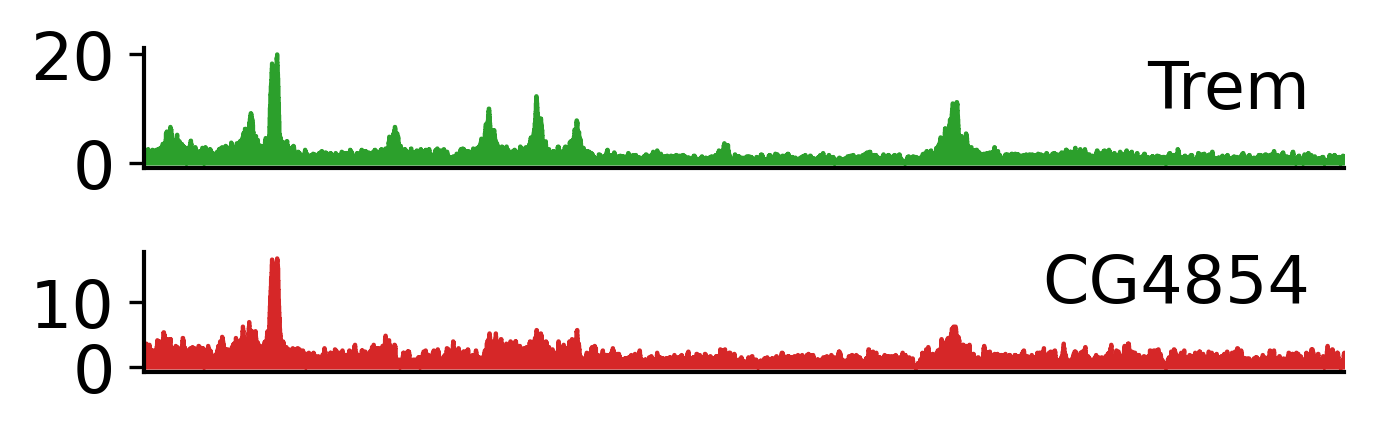

In [41]:
c, s, e = chrom, start-loffset, end + roffset

fig, axs = init_subplots_exact(2,2, dpi=300, y_ratios=[0.1]*2, yspace=1.7)

Trem_vs = target2bbi['Trem'].fetch(c,s,e)
CG4854_vs = target2bbi['CG4854'].fetch(c,s,e)

axs[0].fill_between(np.arange(e-s), Trem_vs, color='#2ca02c', rasterized=True)
axs[1].fill_between(np.arange(e-s), CG4854_vs, color='#d62728', rasterized=True)

axs[0].set_xticks([])
axs[1].set_xticks([])

axs[0].text(50000, 10, 'Trem', ha='right')
axs[1].text(50000, 10, 'CG4854', ha='right')

for ax in axs:
    ax.set_xlim(0, e-s)
    ax.spines[['right', 'top']].set_visible(False)
    for spine in ['left', 'bottom']:  
        ax.spines[spine].set_color('black')  
        ax.spines[spine].set_linewidth(1)  # Decrease spine thickness
# fig.savefig("plots/chip_example_Trem_CG4854.pdf", format="pdf", dpi=300, bbox_inches='tight')


## AAG3 (CG17385)

In [42]:
CG17385_meme_file = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/chip/3_CG17385_AAG3_candidate_own_pipeline/meme_chip/CG17385_top_1000_output.ccut=200/combined.meme'
CG17385_peak_motifs = read_meme(CG17385_meme_file)
CG17385_AAG3_PPM = CG17385_peak_motifs['0 '].T
CG17385_evalue = get_evalues(CG17385_meme_file)['0']

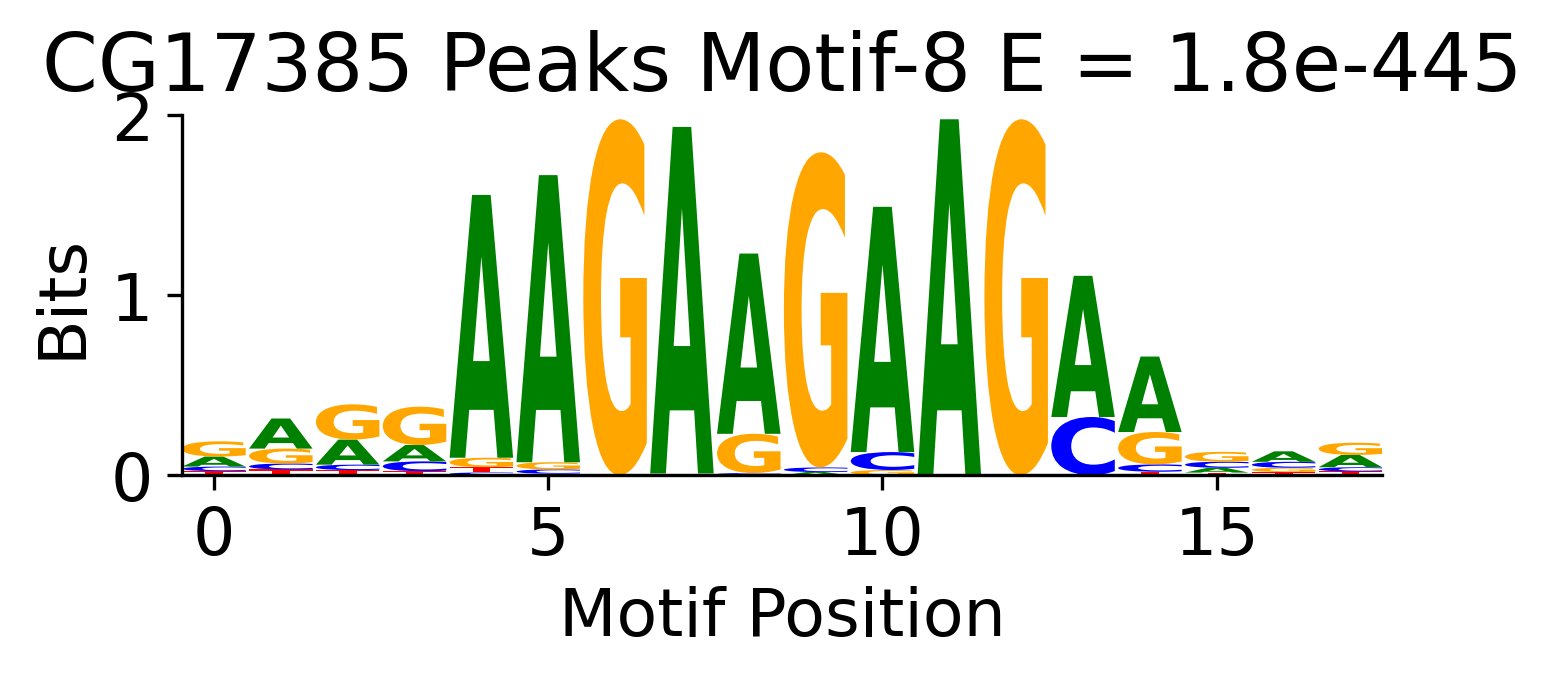

In [43]:
# had to hard code since e-value so low
fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.3])
final_logo_plot(CG17385_AAG3_PPM, ax, 'CG17385 Peaks Motif-8 E = 1.8e-445')

# fig.savefig("plots/CG17385_meme_chip_motif.pdf", format="pdf", dpi=300, bbox_inches='tight')

In [44]:
# Get all boundaries with Motif-8 instance

TFMODISCO_WINDOW=600
out_folder = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/ism_report_1_cutoff/'
modisco_results = h5py.File(f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5","r")
metacluster = modisco_results['neg_patterns']
aag3_instances = pd.DataFrame({
    'idx': metacluster['pattern_15']['seqlets']['example_idx'],
    'start': metacluster['pattern_15']['seqlets']['start'],
    'end': metacluster['pattern_15']['seqlets']['end']
})
modisco_results.close()

fig2_bounds = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_nc14_boundaries_df.bound_score_gt_1.csv')
aag3_bound = fig2_bounds.loc[aag3_instances.idx].drop_duplicates(['chrom','start','end'])


In [45]:
CG17385_bbi = bbi.open('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/run_all_chip_seq/bigwig/CG17385.bw')

In [46]:
boundaries_df['long_str'] = boundaries_df.chrom + ':' + boundaries_df.start.astype(str) + '-' + boundaries_df.end.astype(str)
boundaries_df['CG17385'] = CG17385_bbi.stackup(boundaries_df.chrom, boundaries_df.start, boundaries_df.end, bins=1)

# all boundaries with AAG3
aag3_boundaries = aag3_bound.merge(boundaries_df, on=['chrom', 'start', 'end']).drop_duplicates(['chrom','start','end'])
aag3_strings = aag3_boundaries.long_str

no_aag3_boundaries = boundaries_df.query('~long_str.isin(@aag3_strings)').drop_duplicates(['chrom','start','end'])

model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

# non-boundary
non_bound_df = pd.concat([TRAIN_df, VAL_df, TEST_df]).reset_index(drop=True).query('boundary == 0').rename(columns={"demeaned_ins_score_1": "demeaned_ins_score"}).sample(n=len(no_aag3_boundaries), random_state=10)
non_bound_df['CG17385'] = CG17385_bbi.stackup(non_bound_df.chrom, non_bound_df.start, non_bound_df.end, bins=1)


In [47]:
from scipy.stats import mannwhitneyu
from itertools import combinations

def plot_CG17385_across_groups(pb, pnb, control, ax, title):
    df1_plot = pb[["CG17385"]].copy()
    df1_plot["group"] = f"AAG3 (n={len(df1_plot)})"
    
    df2_plot = pnb[["CG17385"]].copy()
    df2_plot["group"] = f"No AAG3 (n={len(df2_plot)})"
    
    df3_plot = control[["CG17385"]].copy()
    df3_plot["group"] = f"Control (n={len(df3_plot)})"
    
    # Combine all three DataFrames
    df_all = pd.concat([df1_plot, df2_plot, df3_plot], ignore_index=True)
    
    sns.boxplot(
        data=df_all,
        x="group",
        y="CG17385",
        showfliers=False,
        # fliersize=1,
        ax=ax
        # flierprops=dict(marker='o', markersize=1, color='red', alpha=0.5),
    )
    ax.set_ylabel('CG17385 ChIP-seq')
    ax.set_xlabel('')
    plt.xticks(rotation=45)
    # ax.set_title(title)
    # ax.set_ylim([-400, 5000])

    ax.spines[['right', 'top']].set_visible(False)
    for spine in ['left', 'bottom']:  
        ax.spines[spine].set_color('black')  
        ax.spines[spine].set_linewidth(1)  # Decrease spine thickness

    group_col = "group"
    value_col = "CG17385"
    
    groups = df_all[group_col].unique()
    results = []
    
    for g1, g2 in combinations(groups, 2):
        x = df_all[df_all[group_col] == g1][value_col].dropna()
        y = df_all[df_all[group_col] == g2][value_col].dropna()
        
        # test if g1 > g2
        stat, p = mannwhitneyu(x, y, alternative='greater')
        
        results.append({
            "comparison": f"{g1} > {g2}",
            "U_stat": stat,
            "p_value": p
        })
    
    results_df = pd.DataFrame(results)
    display(results_df)

,comparison,U_stat,p_value
0,AAG3 (n=204) > No AAG3 (n=7107),1178830.0,5.896622e-53
1,AAG3 (n=204) > Control (n=7107),1358753.5,3.313009e-101
2,No AAG3 (n=7107) > Control (n=7107),35800202.0,0.000000e+00


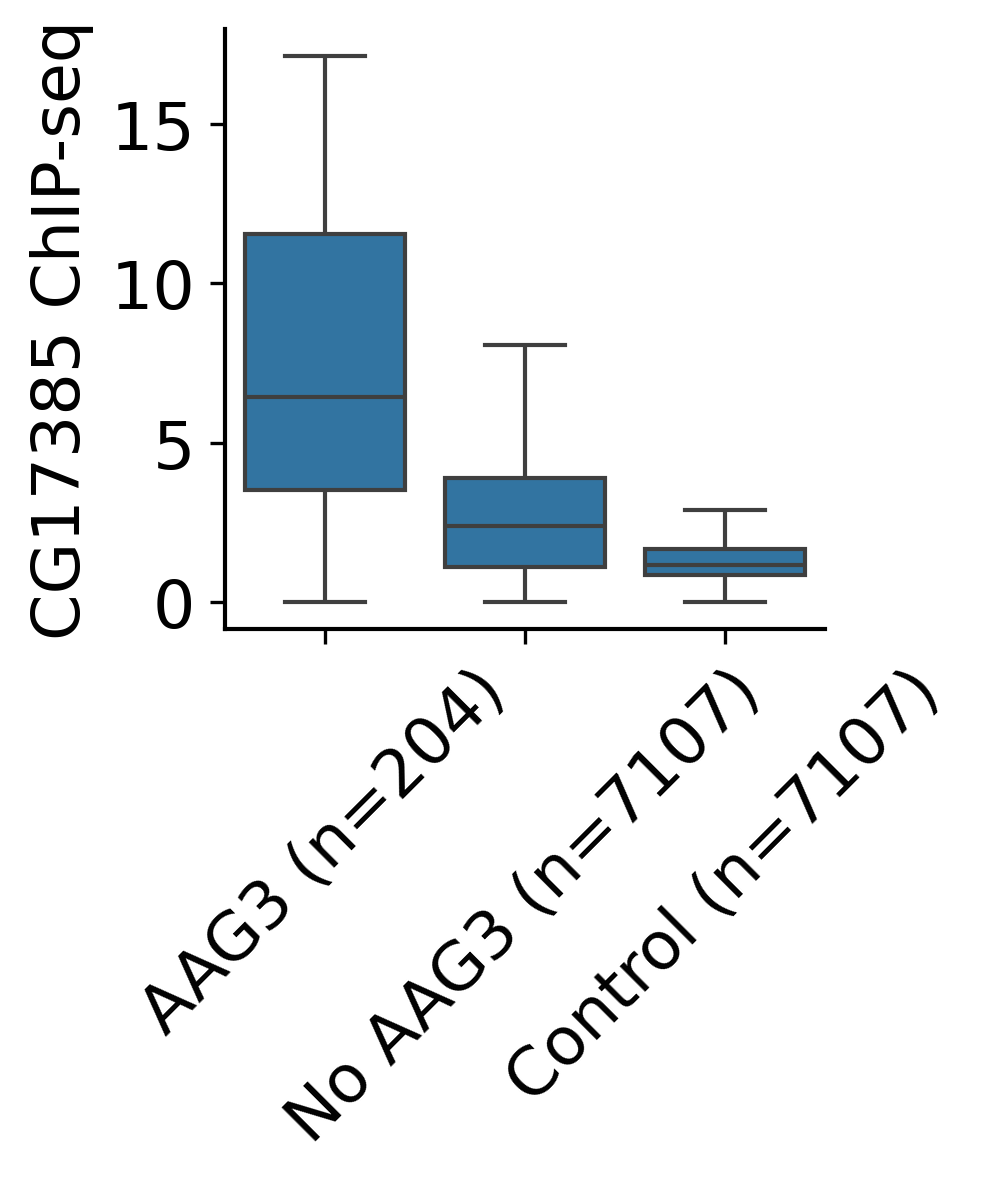

In [48]:
fig, ax = init_subplots_exact(1,1,dpi=300, x_ratios=[0.5], y_ratios=[0.5])
plot_CG17385_across_groups(aag3_boundaries, no_aag3_boundaries, non_bound_df, ax, title='CG17385')
# fig.savefig("plots/CG17385_across_groups_boxplots.pdf", format="pdf", dpi=300, bbox_inches='tight')


In [49]:
import coolbox
from coolbox.api import *

def plot_microc_locus(row, loffset=10_000, roffset=10_000, save_to=None):
    HIC_KWARGS = dict(
        style='window', 
        resolution=200, 
        depth_ratio=0.5, 
        cmap='gist_heat_r', 
        norm='no', 
        transform='log10', 
        max_value=0, 
        min_value=-3, 
        grid=False,
    )
    MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
    chrom, lm = row.chr1, row.mid1
    chrom, rm = row.chr2, row.mid2
    
    frame = [
        coolbox.api.GTF('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/Drosophila_melanogaster.BDGP6.54.115.gtf',
                                                        row_filter="type == 'gene'", color="#000000"), 
        TrackHeight(4),
        coolbox.api.Spacer(1), 
        coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
        coolbox.api.HiCMat(f"{MCOOL_DATA_DIR}/new_nc14_embryo_merged_all_11.mcool", **HIC_KWARGS, title=f"{chrom}:{lm-20_000}-{rm + 20_000}"),
        coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
        coolbox.api.BigWig('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/chip/bws/fig3_bws/CG17385.bw', title='CG17385', color='blue'),
    
    ]
    from functools import reduce
    
    frame = reduce(lambda x, y: x + y, frame)
    print(f"{chrom}:{lm-loffset}-{rm + roffset}")
    fig = frame.plot(f"{chrom}:{lm-loffset}-{rm + roffset}")
    fig.set(facecolor="white")
    if save_to:
        fig.savefig(save_to, format="pdf")
    display(fig).query('start == @start')

[ERROR:tab.py:300 -                query()] Reference sequence chrX not found in index header.


chrX:4570000-4677200


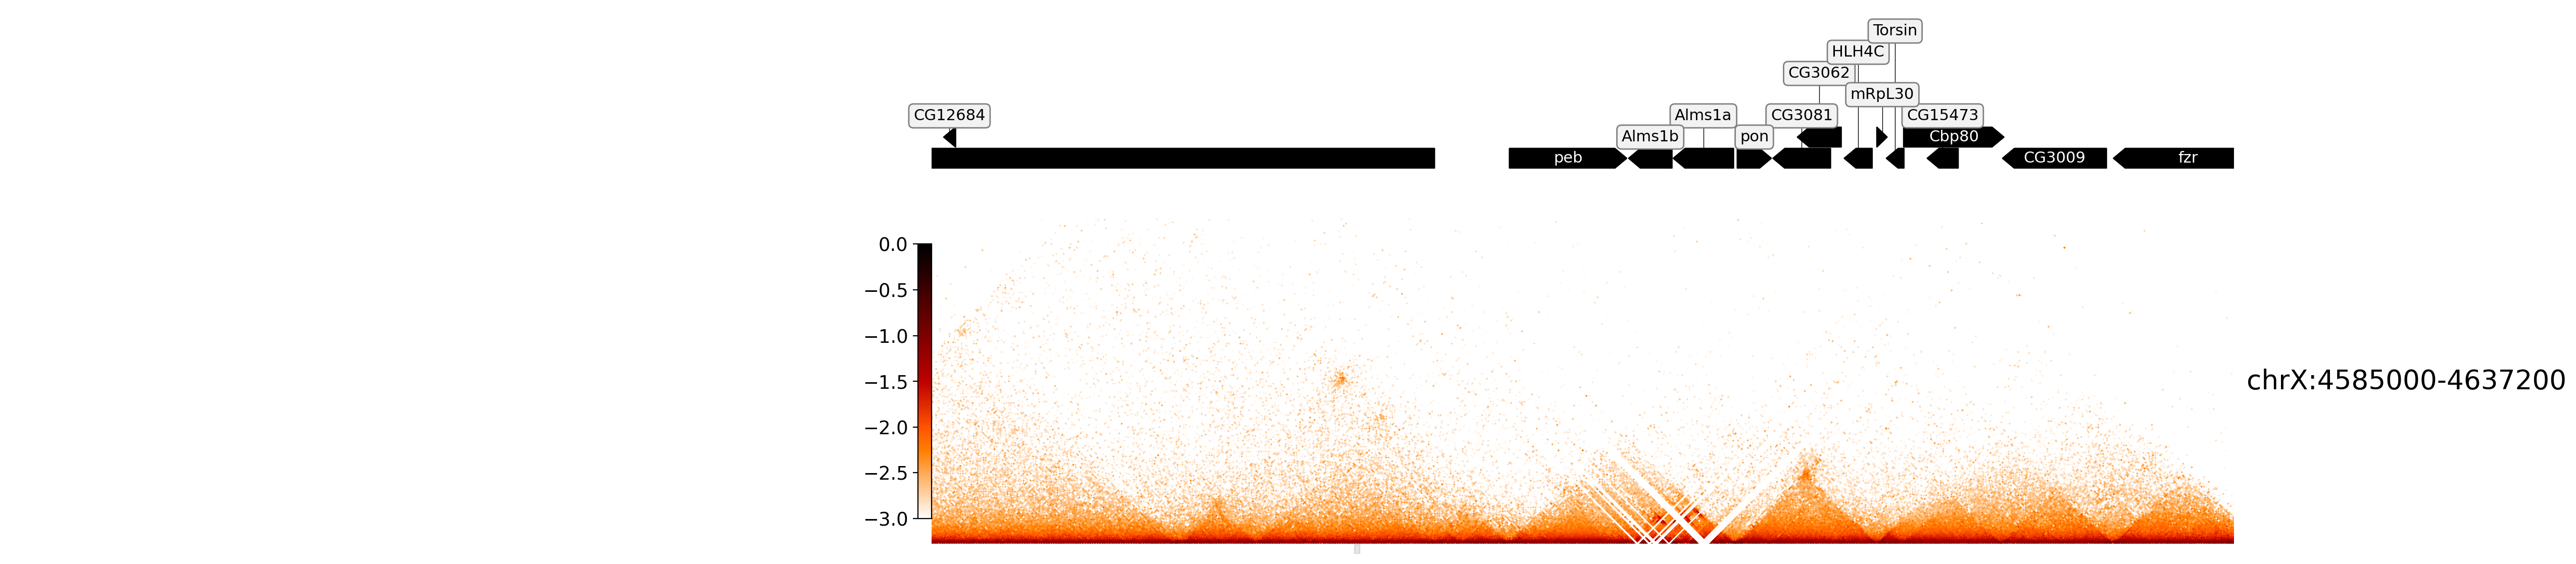

In [50]:
# matplotlib inline
loffset=35_000
roffset=60_000
HIC_KWARGS = dict(
        style='window', 
        resolution=200, 
        depth_ratio=0.5, 
        cmap='gist_heat_r', 
        norm='no', 
        transform='log10', 
        max_value=0, 
        min_value=-3, 
        grid=False,
    )
MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
chrom, start, end = 'chrX', 4570000 + loffset, 4677200 - roffset

frame = [
    coolbox.api.GTF('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/Drosophila_melanogaster.BDGP6.54.115.gtf',
                                                    row_filter="type == 'gene'", color="#000000"), 
    TrackHeight(4),
    coolbox.api.Spacer(1), 
    coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
    coolbox.api.HiCMat(f"{MCOOL_DATA_DIR}/new_nc14_embryo_merged_all_11.mcool", **HIC_KWARGS, title=f"{chrom}:{start-20_000}-{end + 20_000}"),
    coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
    coolbox.core.coverage.HighLights(f'{chrom}:{start - 200}-{start + 200}', color='black', alpha=0.1),
]
from functools import reduce

frame = reduce(lambda x, y: x + y, frame)
print(f"{chrom}:{start-loffset}-{end + roffset}")
fig = frame.plot(f"{chrom}:{start-loffset}-{end + roffset}")
fig.set(facecolor="white")
fig.savefig("plots/AAG3_locus.pdf", format="pdf", dpi=300, bbox_inches='tight')
display(fig)

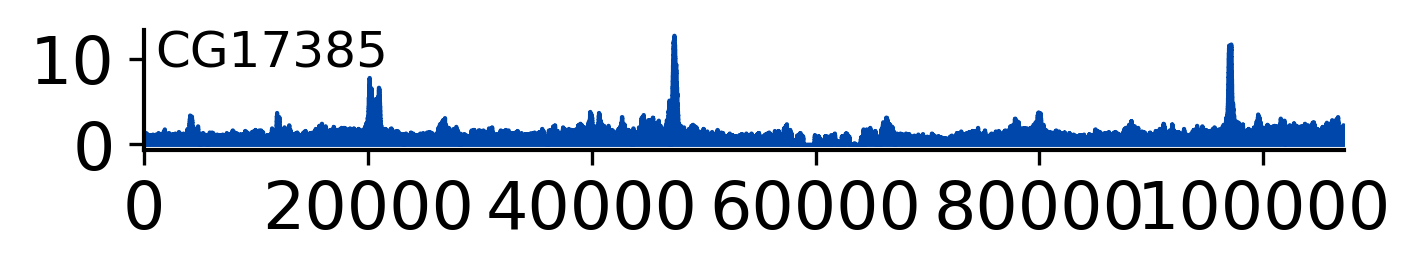

In [51]:
fig, ax = init_subplots_exact(1,1, dpi=300, y_ratios=[0.1])

c, s, e = 'chrX', 4570000, 4677200
plt.fill_between(np.arange(e-s), CG17385_bbi.fetch(c, s, e), color='#0047AB', rasterized=True)
plt.xlim(0, e-s)

ax.text(1000, 9, 'CG17385', fontsize=12)

ax.set_xlim(0, e-s)
ax.spines[['right', 'top']].set_visible(False)
for spine in ['left', 'bottom']:  
    ax.spines[spine].set_color('black')  
    ax.spines[spine].set_linewidth(1)  # Decrease spine thickness
        
# fig.savefig("plots/AAG3_example_CG17385.pdf", format="pdf", dpi=300, bbox_inches='tight')
